# Projet tutoré — Classification automatique de documents médicaux hétérogènes

### Encadrant
Zakariyaa ISMAILI

### Binôme
- Kadidiatou Dem
- Hiba Chach

### Objectif
Explorer et analyser les datasets + (OCR+ML).

## Phase 1 — Setup et Exploration des Données

In [1]:
import os
from pathlib import Path
from glob import glob
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from tqdm.auto import tqdm
import pytesseract
from PIL import Image
import os
import hashlib
import cv2
import re
import time
import joblib
import easyocr
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.model_selection import cross_val_score
from sklearn.model_selection import StratifiedKFold
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    precision_recall_curve
)
import pytesseract



In [2]:
import os

print(os.listdir("/kaggle/working"))

['.virtual_documents']


In [3]:
RVL_PATH = Path("/kaggle/input/datasets/orllem456/rvlcdip")
MED_PATH = Path("/kaggle/input/datasets/andrewmvd/medical-mnist")

print("RVL exists:", RVL_PATH.exists())
print("MED exists:", MED_PATH.exists())

RVL exists: True
MED exists: True


============================
— RVL-CDIP
============================

In [4]:
splits = ["train", "val", "test"]
data = []
for split in splits:
    label_file = RVL_PATH / "labels" / f"{split}.txt"
    
    with open(label_file, "r") as f:
        for line in f:
            path, label = line.strip().split()
            data.append((path, int(label), split))
df_rvl = pd.DataFrame(data, columns=["path", "label", "split"])
df_rvl.head()

,path,label,split
0,imagesq/q/o/c/qoc54c00/80035521.tif,15,train
1,imagese/e/w/c/ewc23d00/513280028.tif,1,train
2,imagesw/w/b/t/wbt26e00/2053453161.tif,7,train
3,imagesm/m/k/m/mkm05e00/2040792992_2040792994.tif,10,train
4,imageso/o/e/x/oex80d00/522787731+-7732.tif,3,train


In [5]:
df_rvl["label"].unique()

array([15,  1,  7, 10,  3, 14, 11, 13,  0,  2,  9,  4, 12,  5,  6,  8])

In [6]:
rvl_classes = [
"letter","form","email","handwritten","advertisement",
"scientific report","scientific publication","specification",
"file folder","news article","budget","invoice",
"presentation","questionnaire","resume","memo"
]

df_rvl["class_name"] = df_rvl["label"].map(lambda x: rvl_classes[x])

In [7]:
df_rvl["class_name"].value_counts()

class_name
memo                      25000
form                      25000
specification             25000
budget                    25000
handwritten               25000
resume                    25000
invoice                   25000
questionnaire             25000
letter                    25000
email                     25000
news article              25000
advertisement             25000
presentation              25000
scientific report         25000
scientific publication    25000
file folder               25000
Name: count, dtype: int64

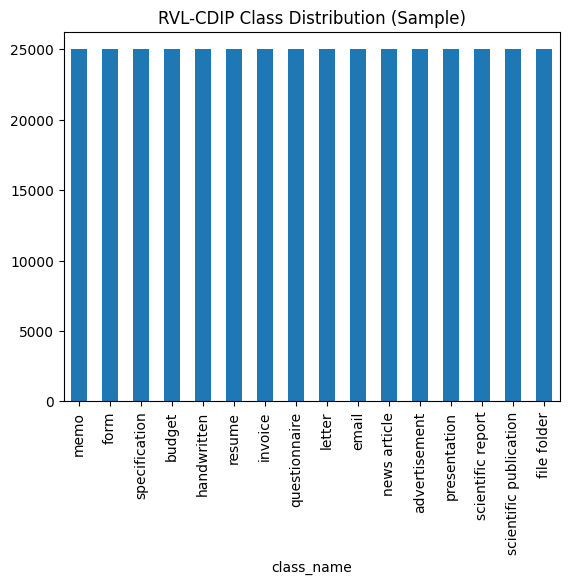

In [8]:
df_rvl["class_name"].value_counts().plot(kind="bar")
plt.title("RVL-CDIP Class Distribution (Sample)")
plt.show()

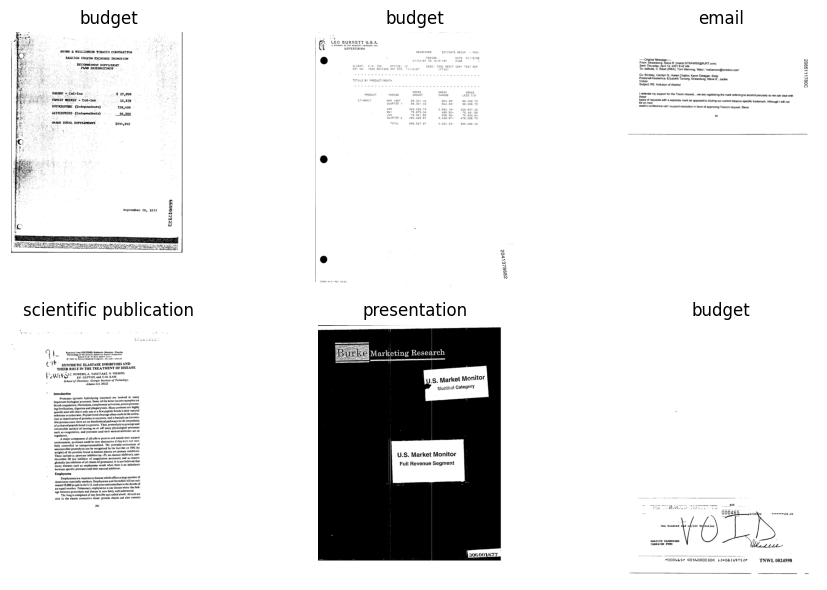

In [9]:
fig, ax = plt.subplots(2,3, figsize=(10,6))

sample = df_rvl.sample(6)

for i,(idx,row) in enumerate(sample.iterrows()):
    img_path = RVL_PATH / "images" / row["path"]
    img = Image.open(img_path)
    
    ax[i//3,i%3].imshow(img, cmap="gray")
    ax[i//3,i%3].set_title(row["class_name"])
    ax[i//3,i%3].axis("off")

plt.tight_layout()
plt.show()

In [10]:
import re
ocr_results = []
sample_ocr = df_rvl.sample(50, random_state=42)
config = r'--oem 3 --psm 6'
for idx, row in tqdm(sample_ocr.iterrows(), total=50):
    img_path = RVL_PATH / "images" / row["path"]
    img = Image.open(img_path)
    text = pytesseract.image_to_string(img,config=config)
    text_clean = re.sub(r'\s+', ' ', text).strip()
    ocr_results.append({
            "classe": row["class_name"],
            "nb_caracteres": len(text_clean),
            "texte_present": len(text_clean) > 10,
            "text": text_clean
        })

  0%|          | 0/50 [00:00<?, ?it/s]

In [11]:
ocr_df = pd.DataFrame(ocr_results)
ocr_df

,classe,nb_caracteres,texte_present,text
0,handwritten,223,True,Hea &j i fe. Mi Aiskeng Manet ws loor px Ape “...
1,scientific report,362,True,"‘ BORRISTON LABORATORIES, INC. INDUCTION OF HE..."
2,scientific report,1398,True,REPORT P 0268/2156 SZA2SKAB OUP We “i iit ghe ...
3,resume,1920,True,BIOGRAPHICAL SKETCH Personal Data ‘ James B. K...
4,file folder,90,True,i i 5 a — hy Re oS eg “48. SY oR 8 De x E a : ...
5,invoice,770,True,i : z 2 rom Pl 3 3 5 i ae8] Be ere 33 2 we Bee...
6,file folder,1094,True,1 gins 3 Seah ieee i oe Se erate hn) i big Tie...
7,scientific report,526,True,INBIFO Institut for biologische Forschung GmbH...
8,questionnaire,1417,True,eo ey - LEE Mo. : : : ‘ sob +0906 : Bellomy-Ca...
9,news article,2230,True,"WASHINGTON POST Washington, D.C. April 16, 196..."


/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 12 () missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


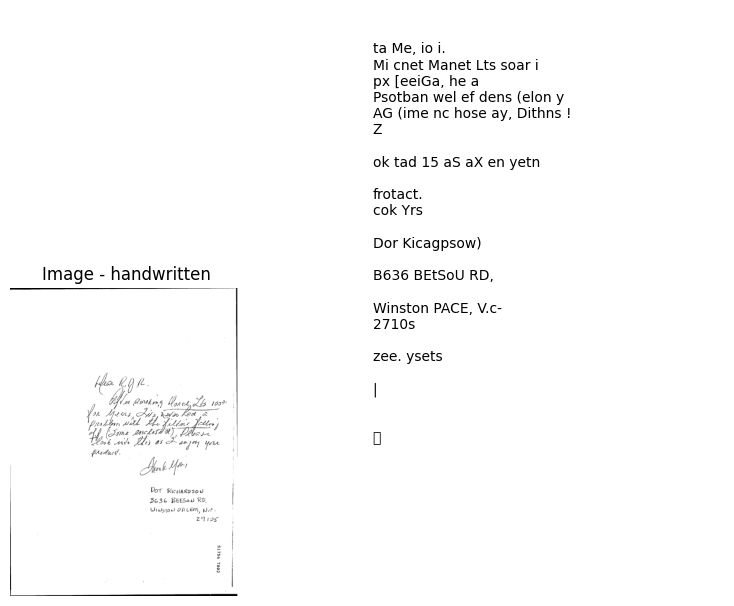

/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 12 () missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


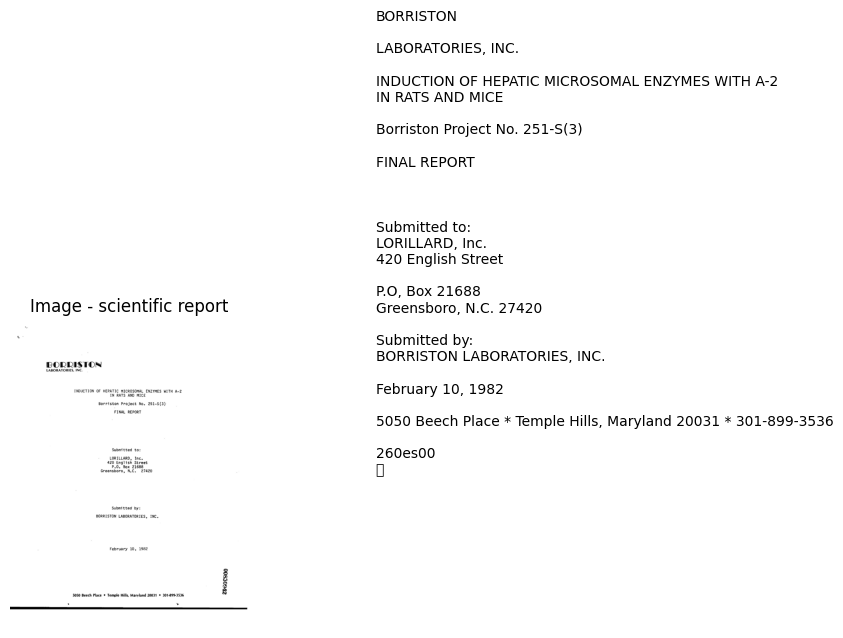

/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 12 () missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


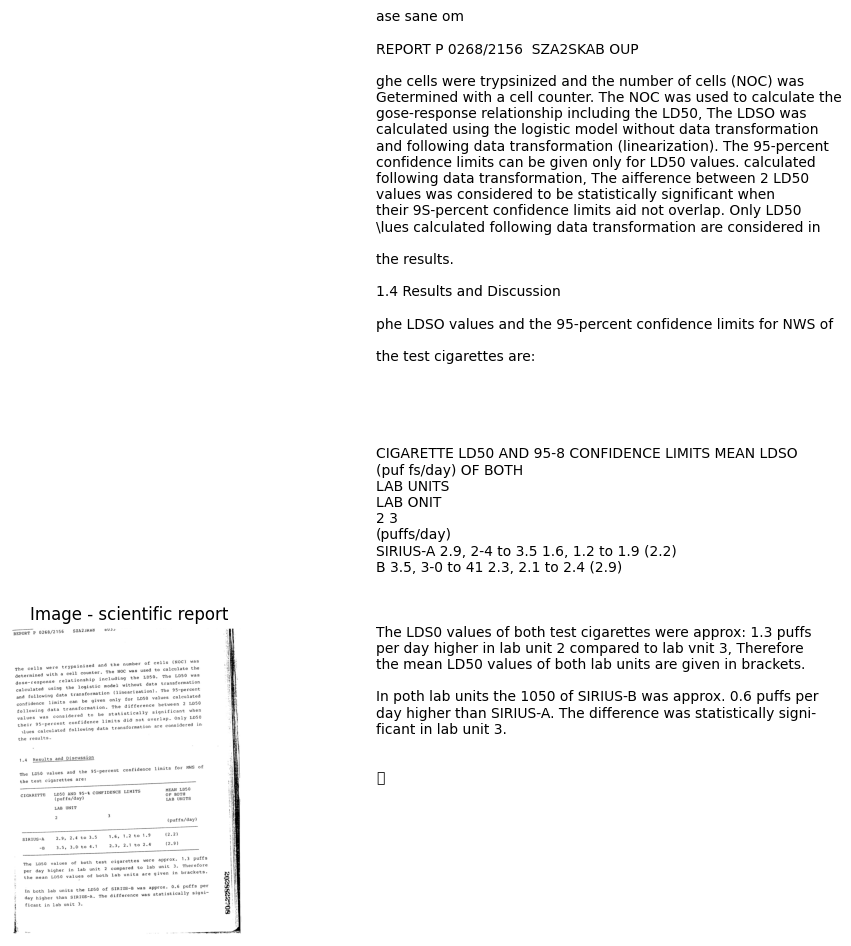

/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 12 () missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


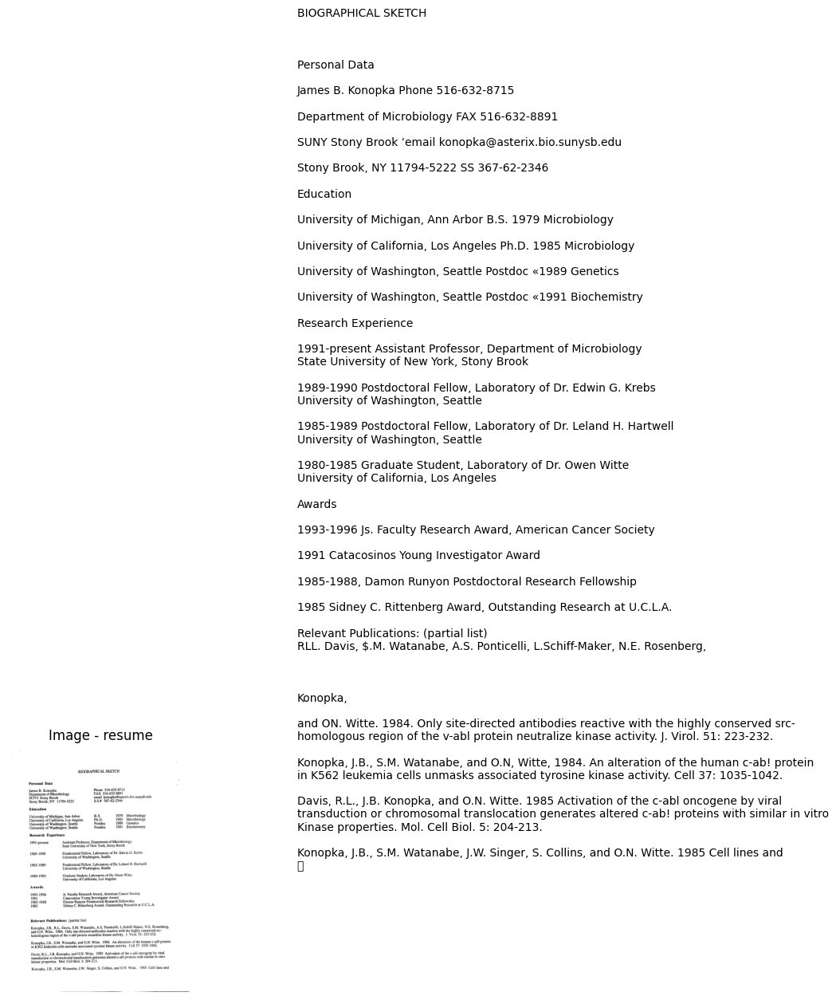

/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 12 () missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


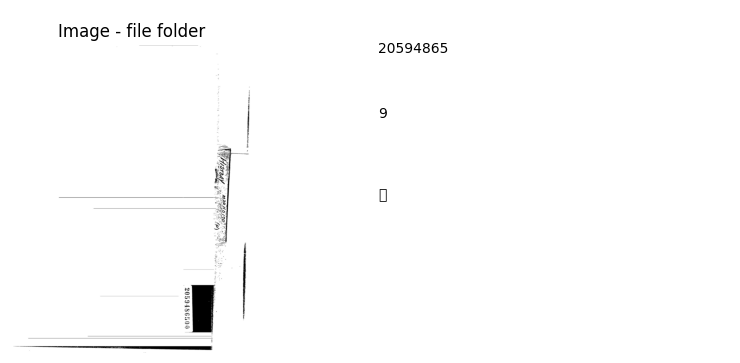

/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 12 () missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


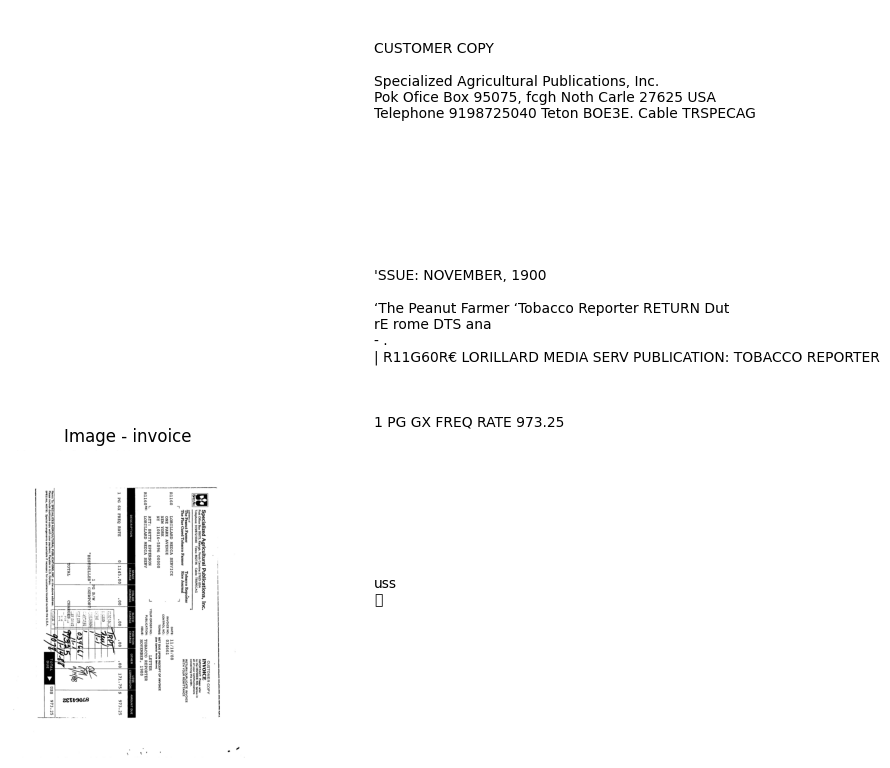

/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 12 () missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


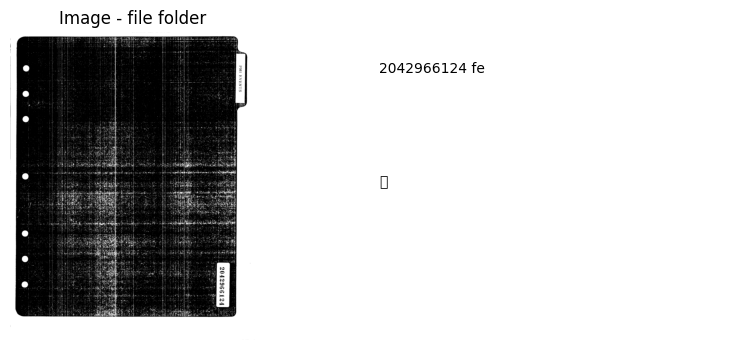

/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 12 () missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


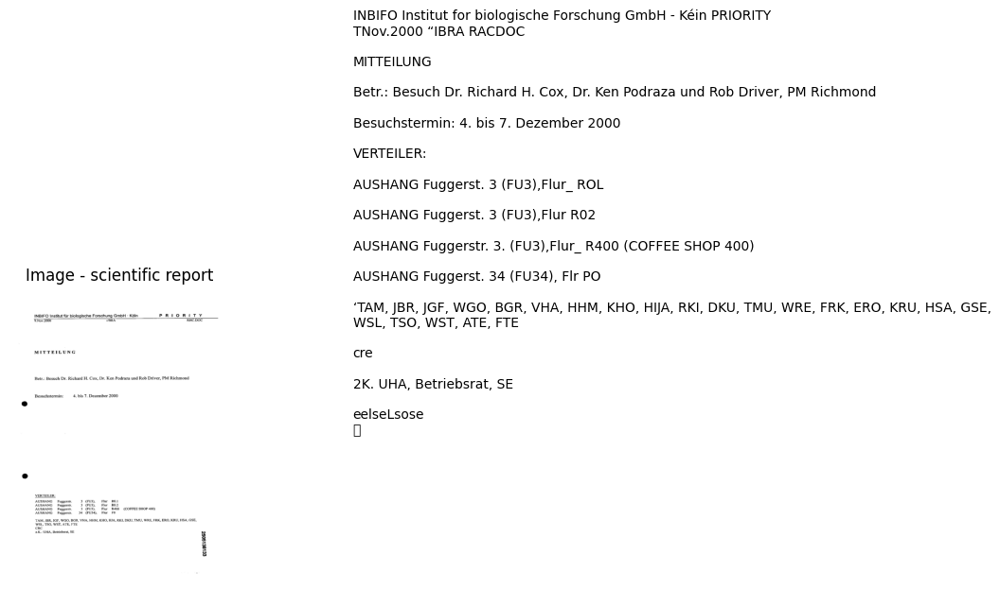

/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 12 () missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


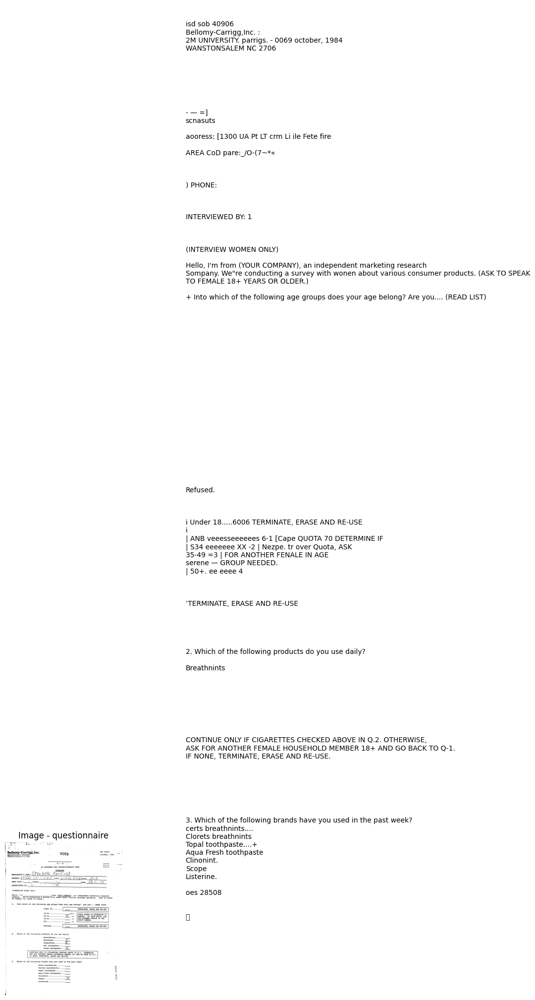

/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 12 () missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


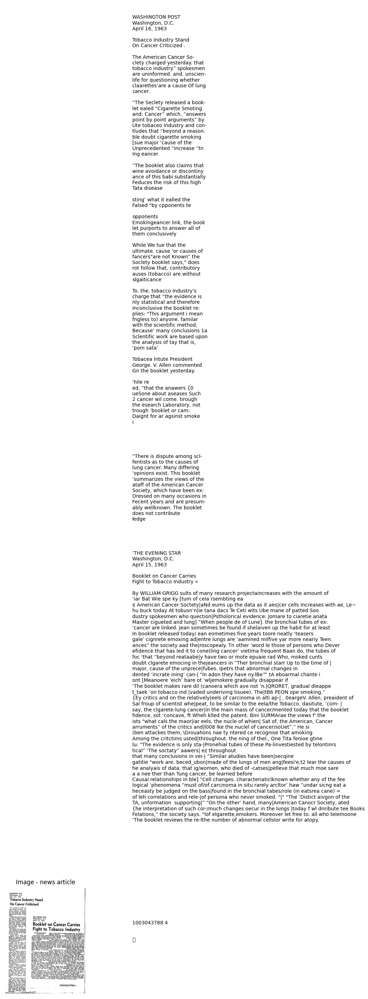

/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 12 () missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


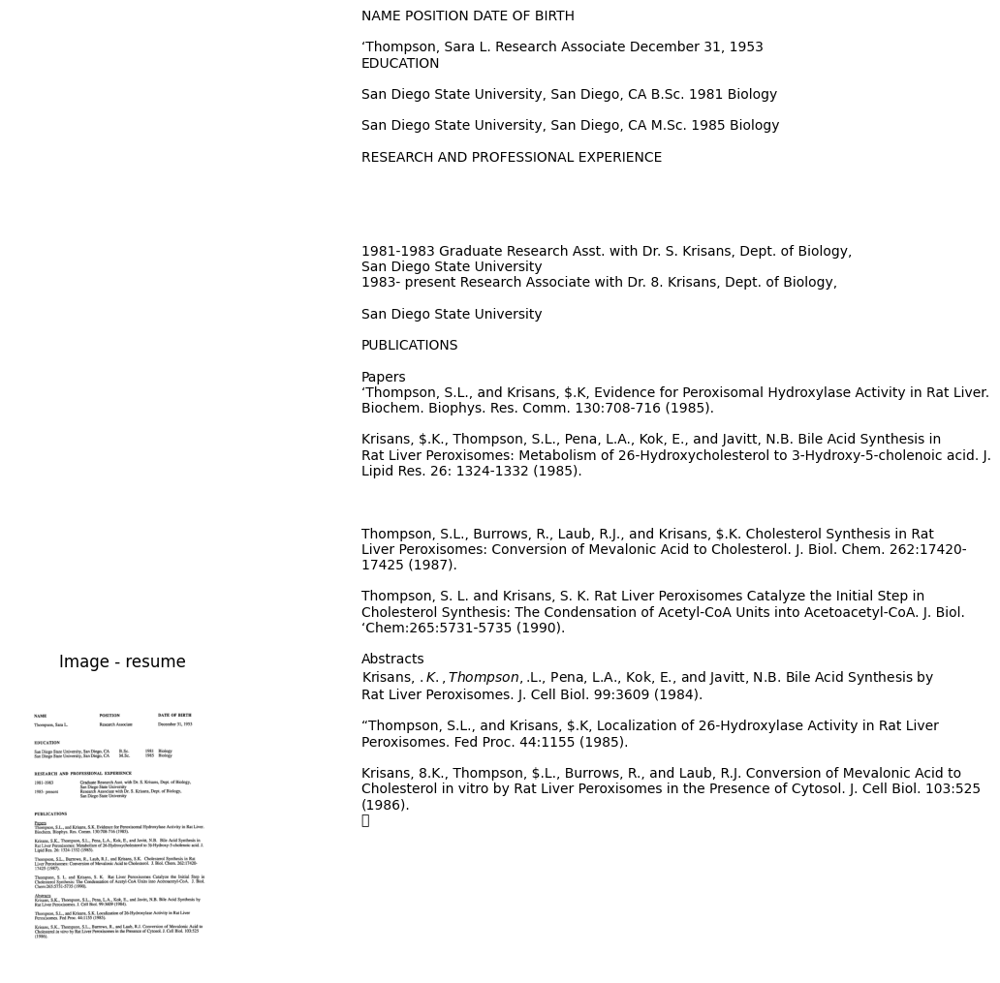

/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 12 () missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


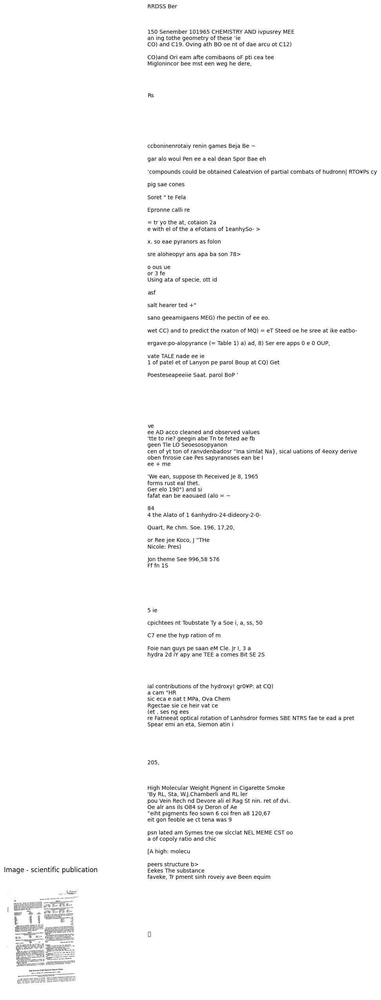

/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 12 () missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


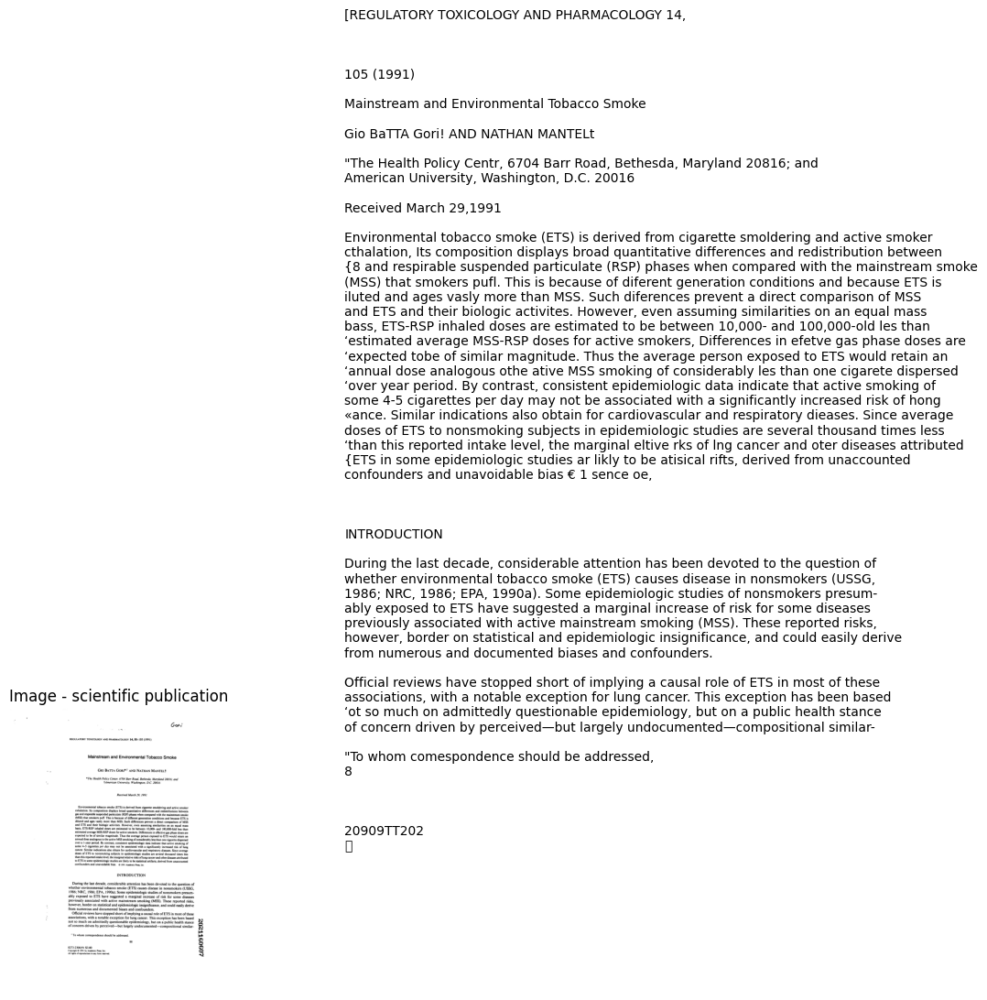

/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 12 () missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


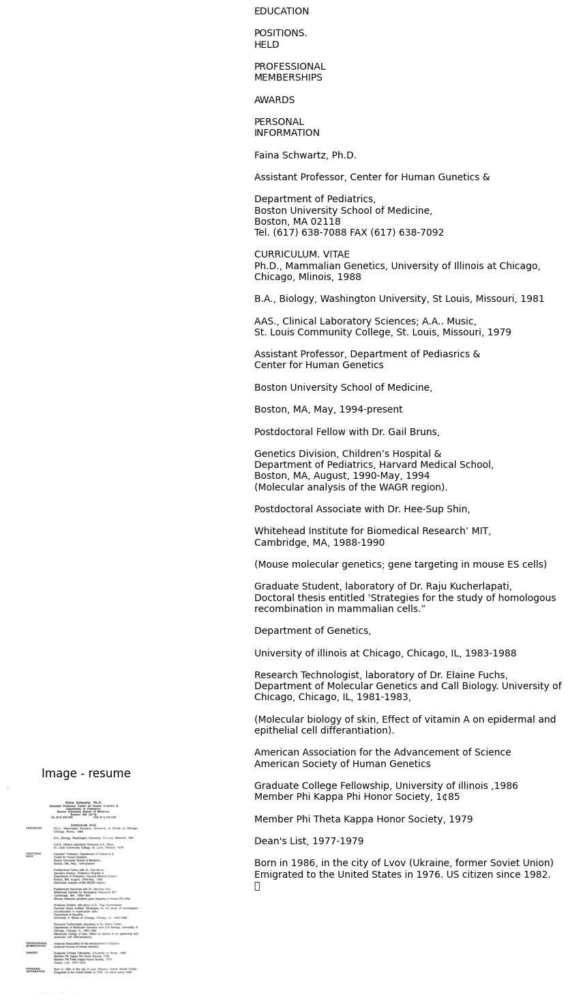

/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 12 () missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


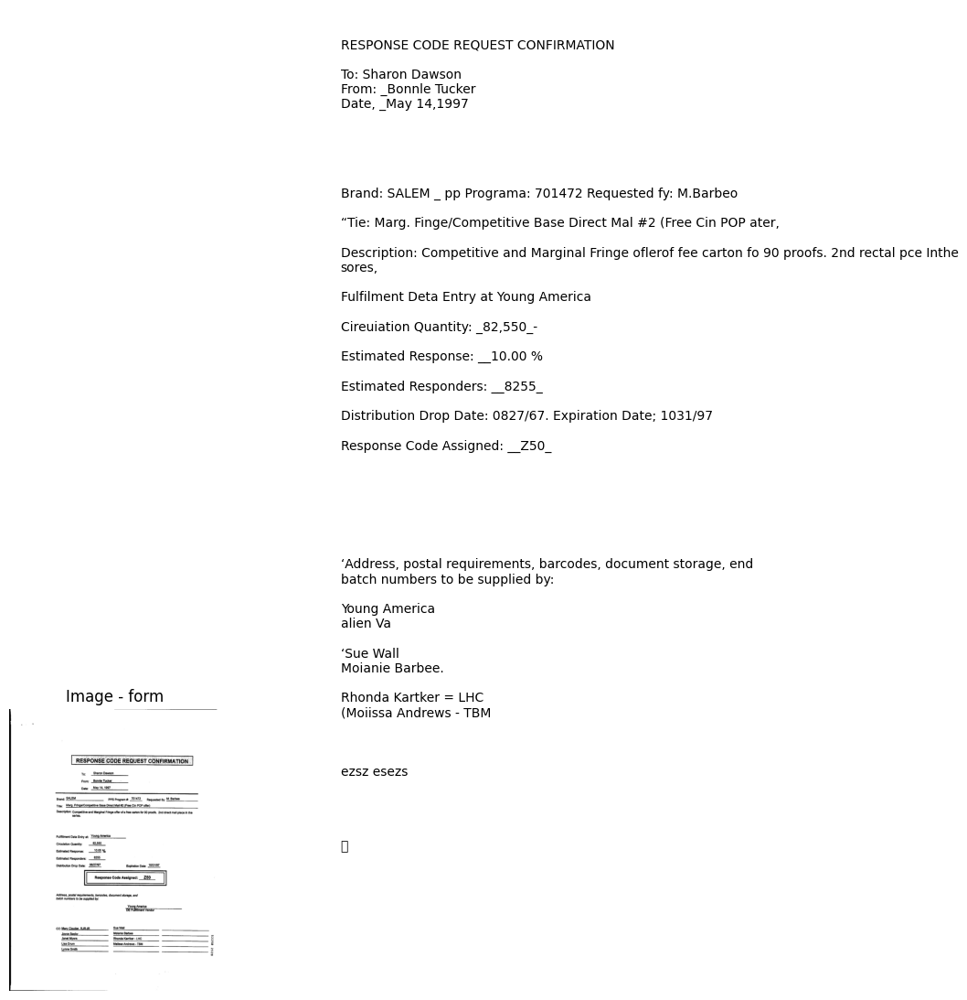

/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 12 () missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


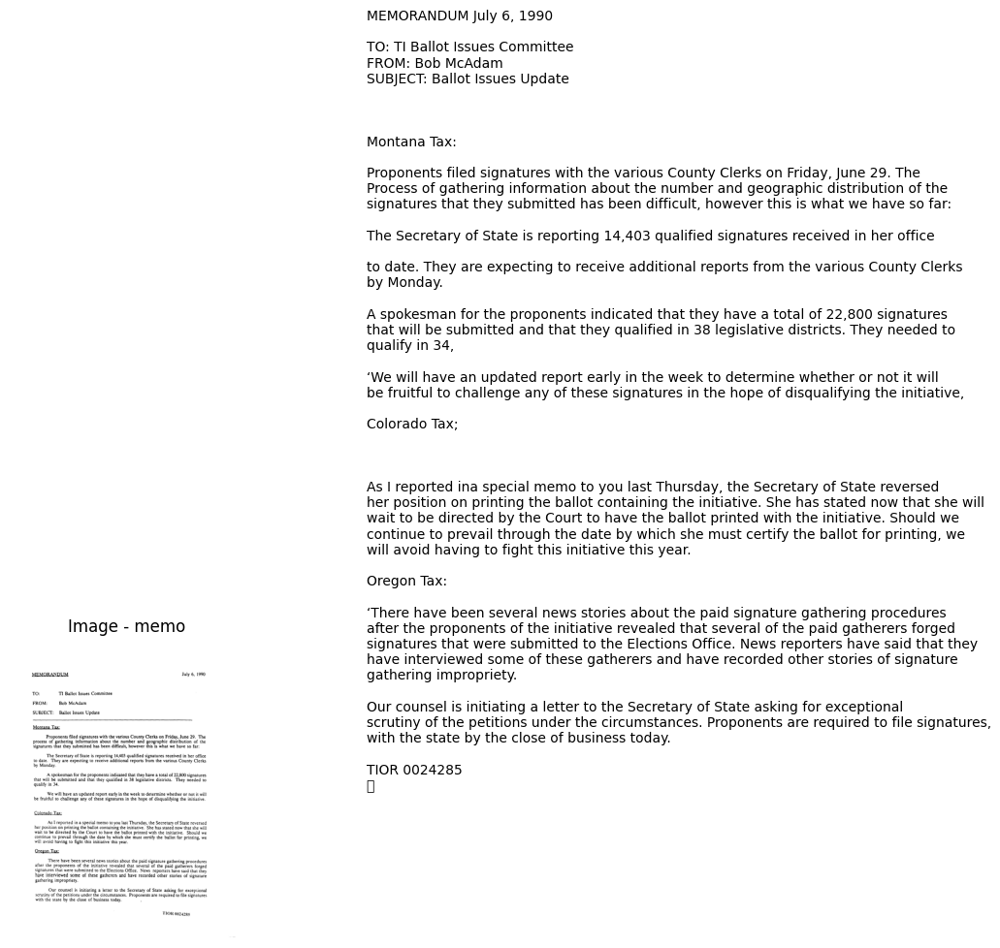

/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 12 () missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


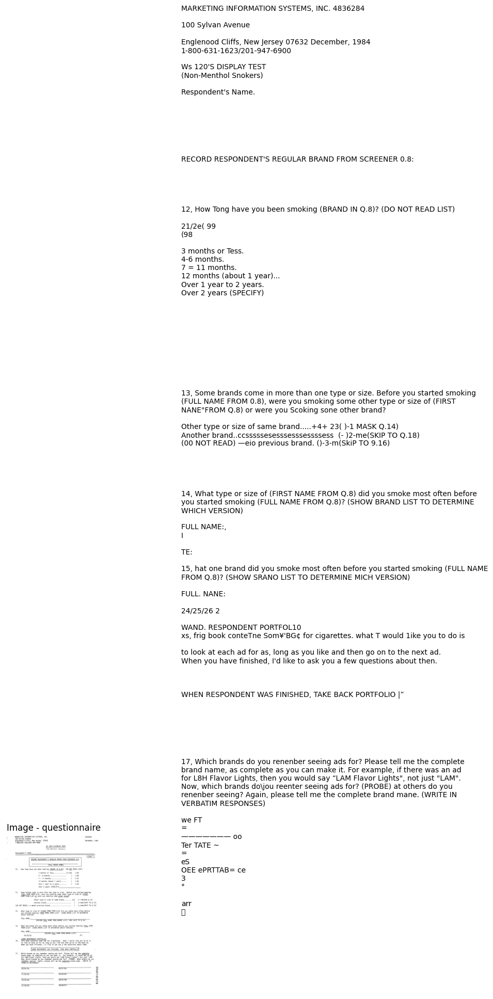

/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 12 () missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


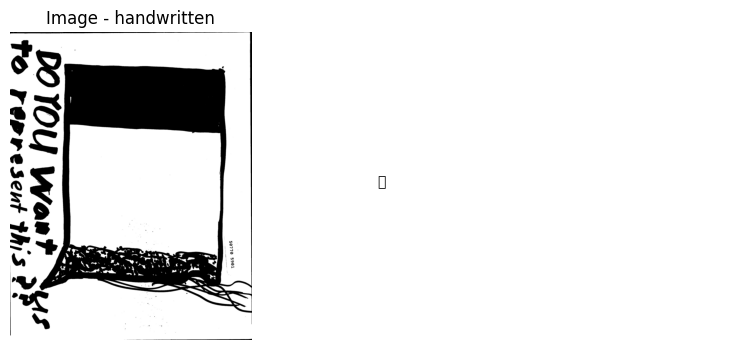

/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 12 () missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


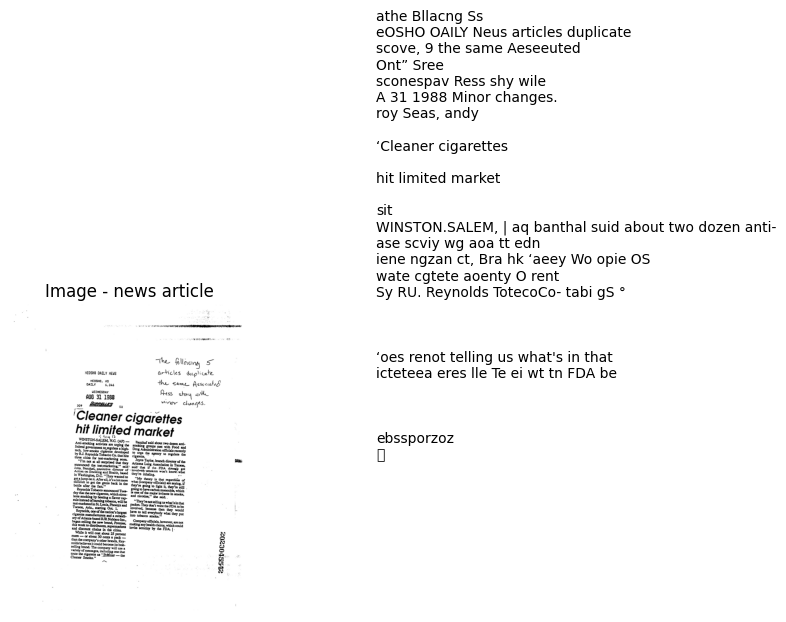

/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 12 () missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


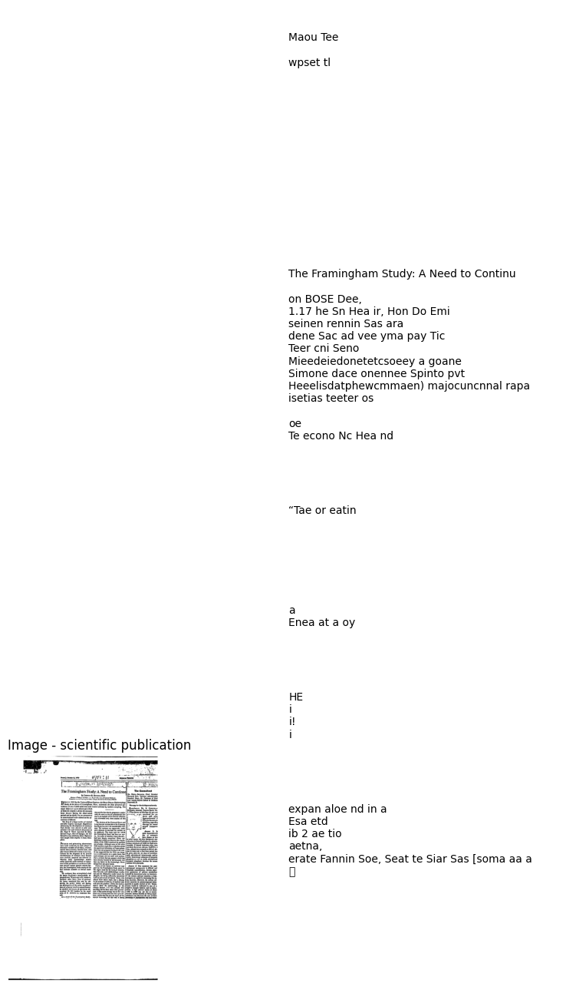

/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 12 () missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


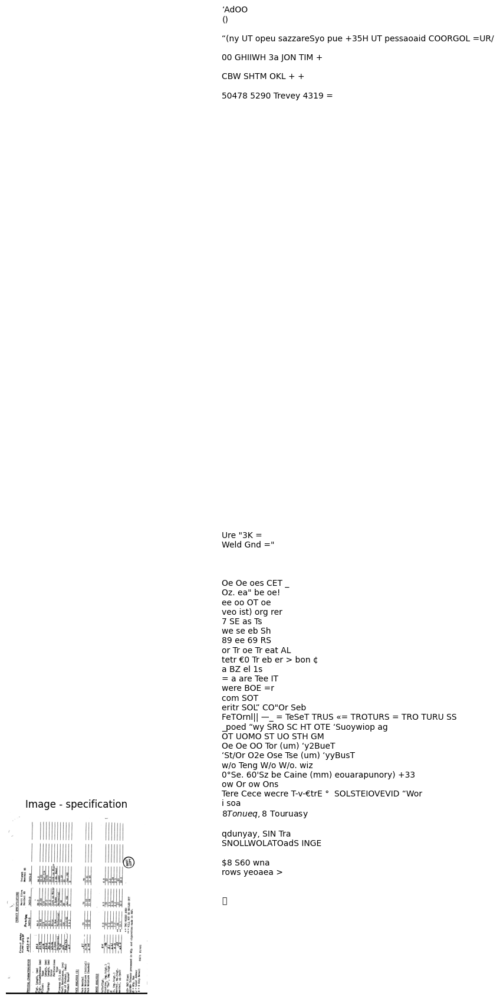

/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 12 () missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


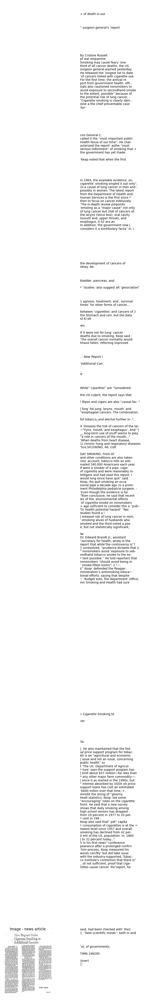

/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 12 () missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


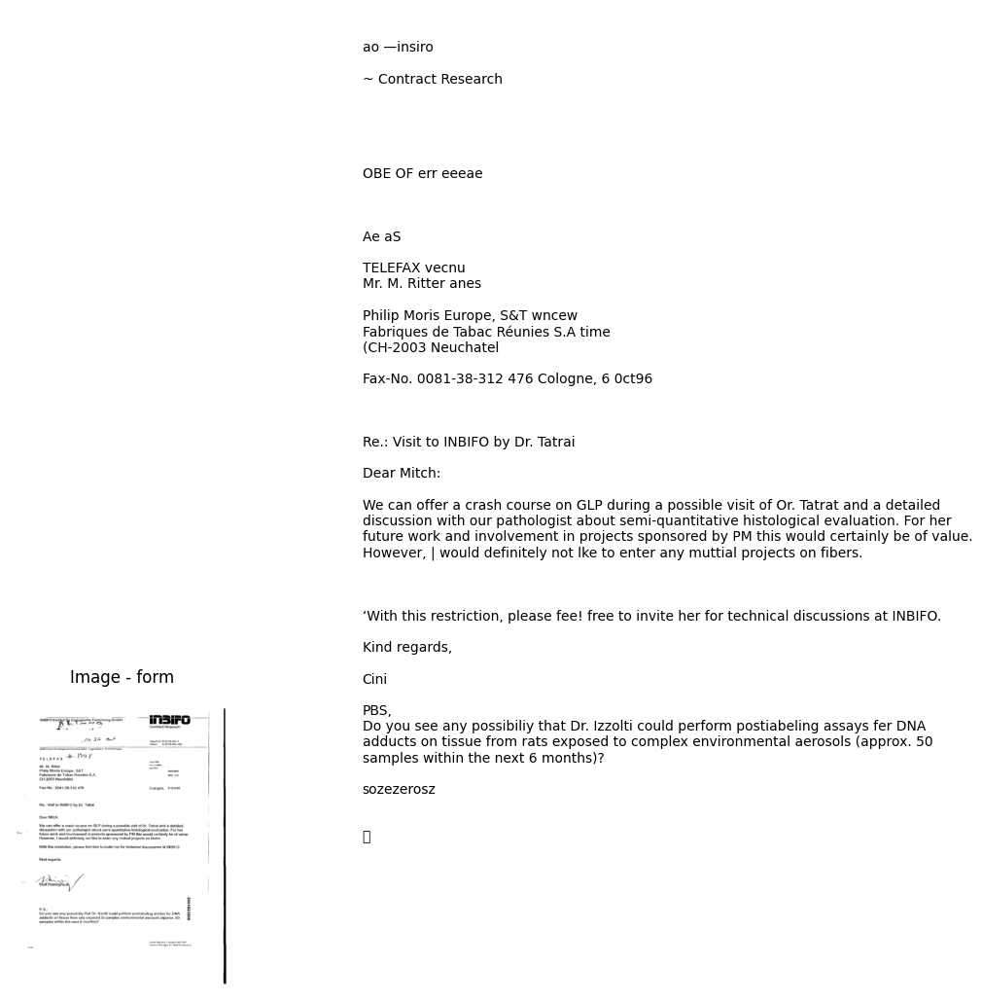

/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 12 () missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


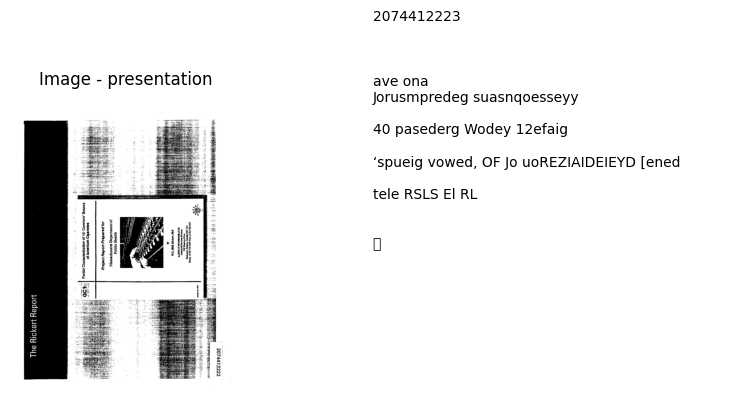

/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 12 () missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


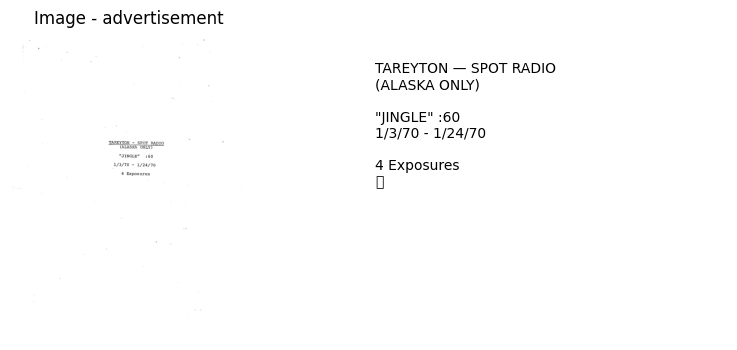

/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 12 () missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


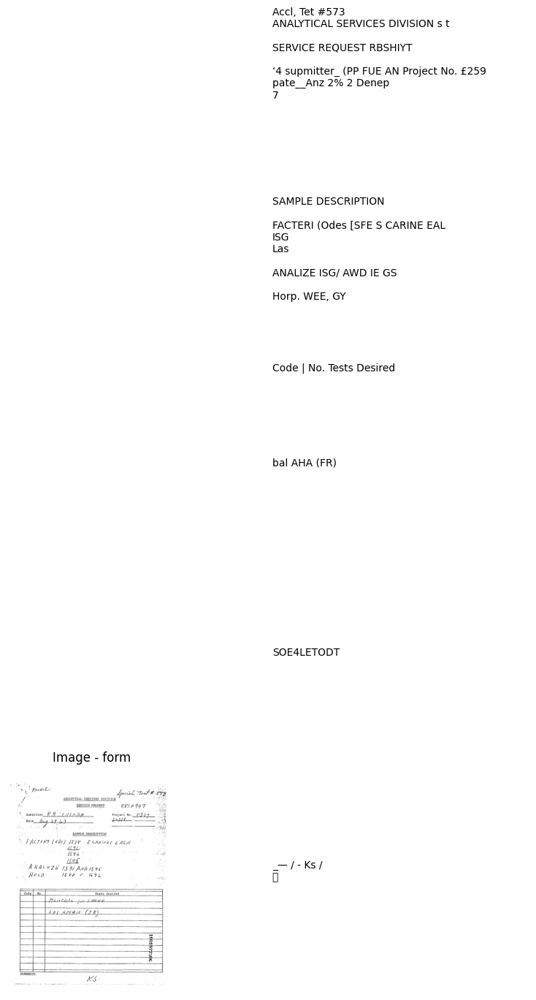

/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 12 () missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


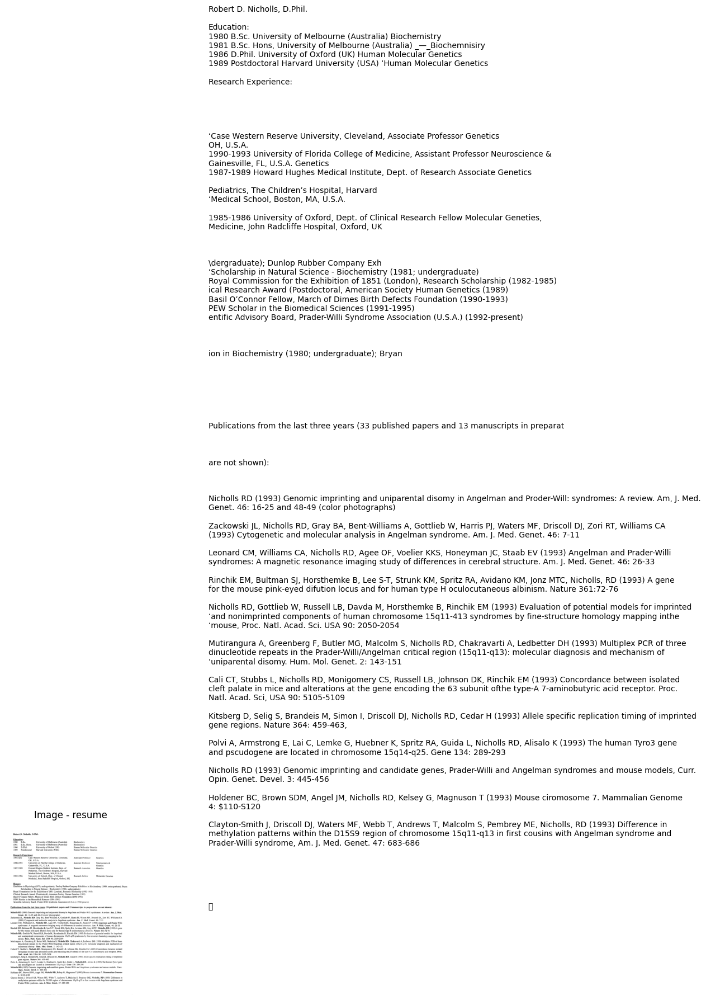

/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 12 () missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


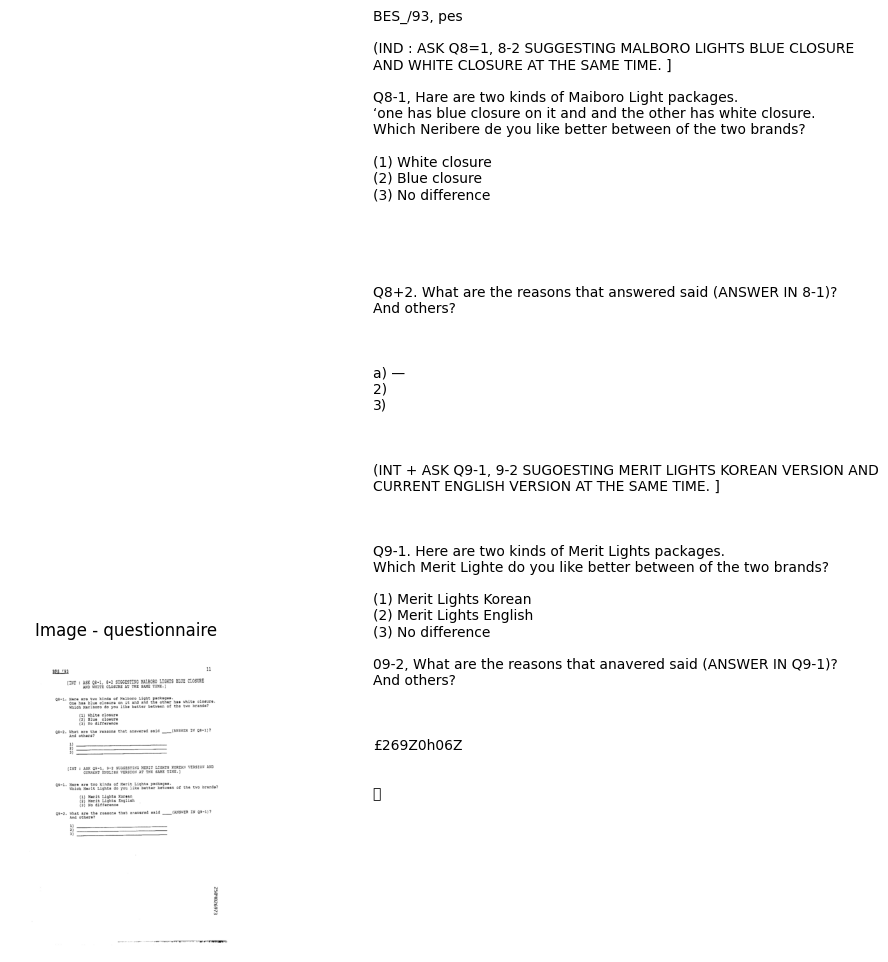

/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 12 () missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


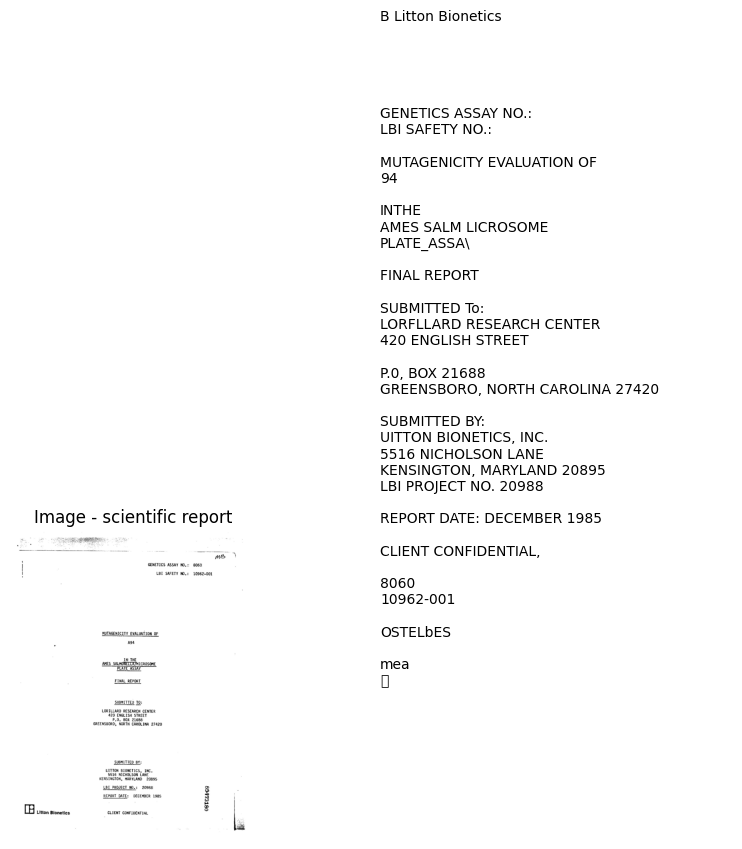

/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 12 () missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


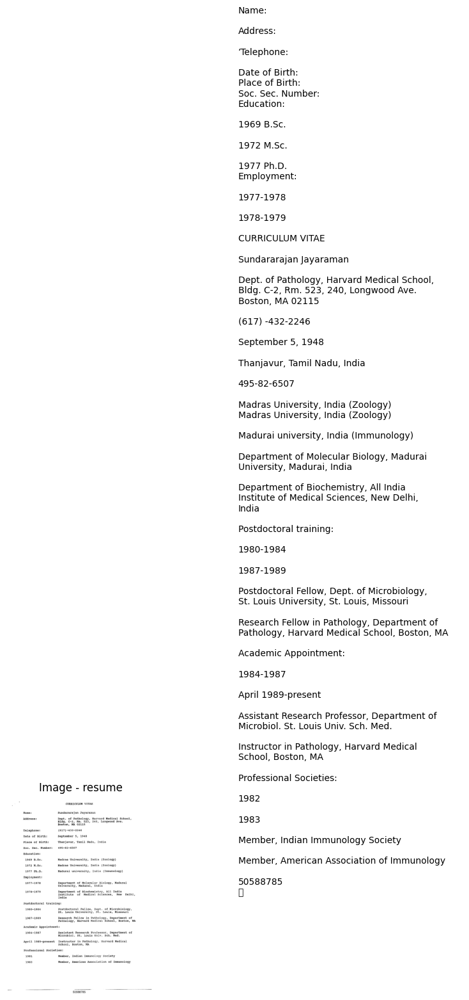

/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 12 () missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


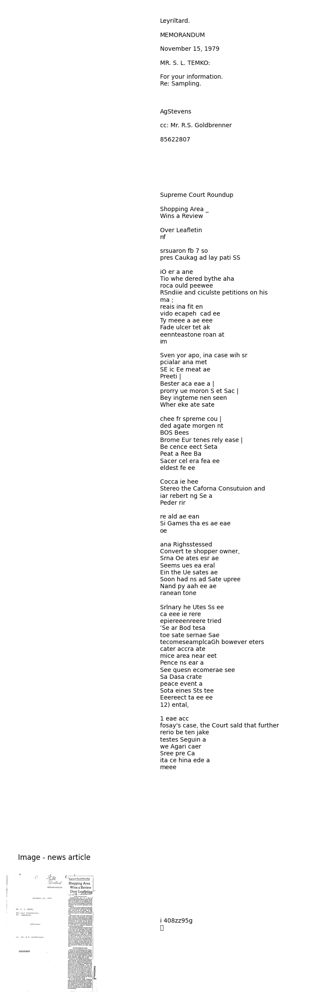

/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 12 () missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


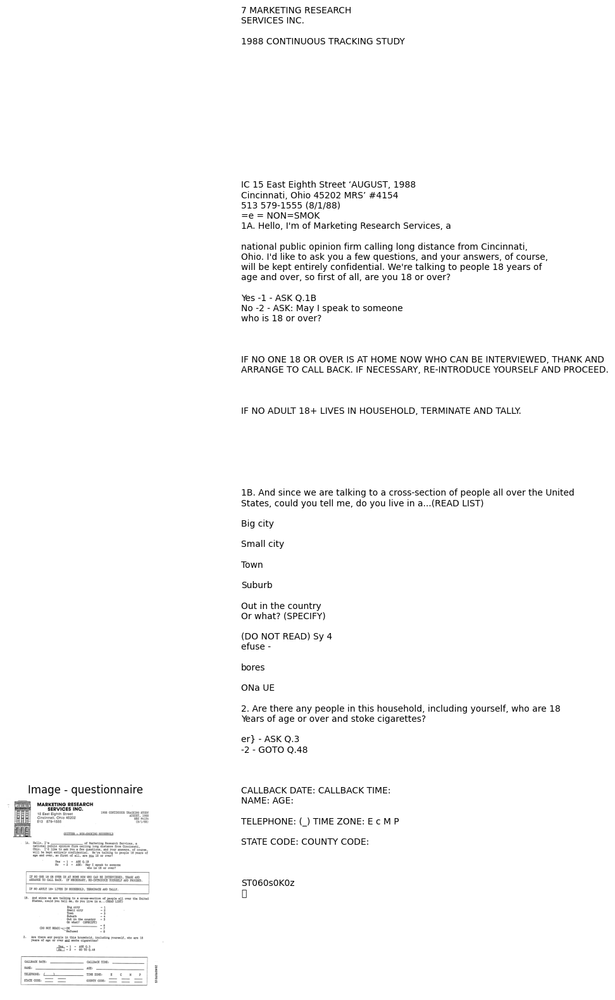

/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 12 () missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


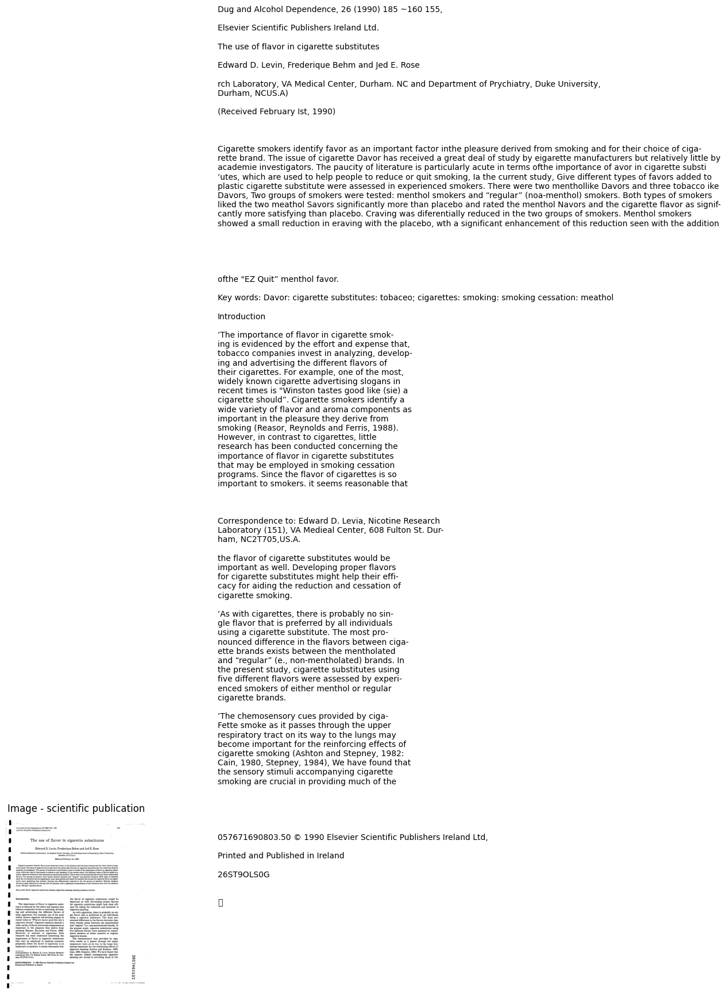

/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 12 () missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


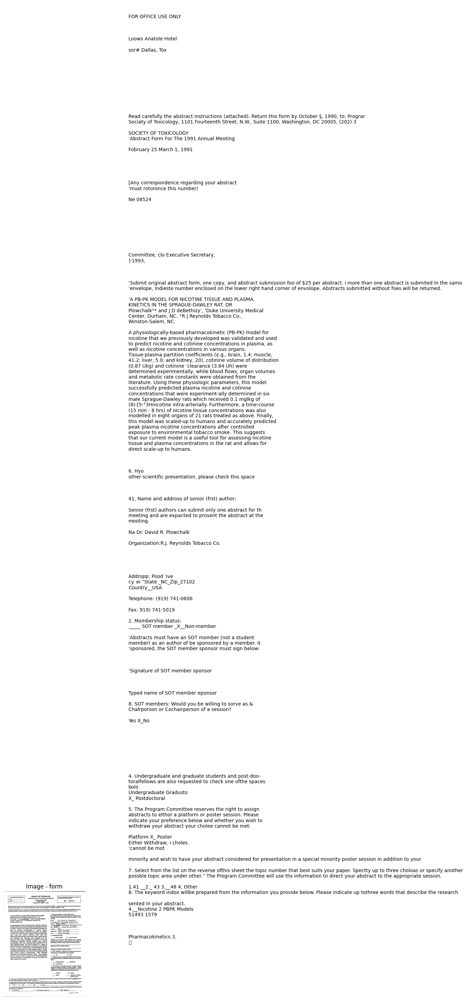

/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 12 () missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


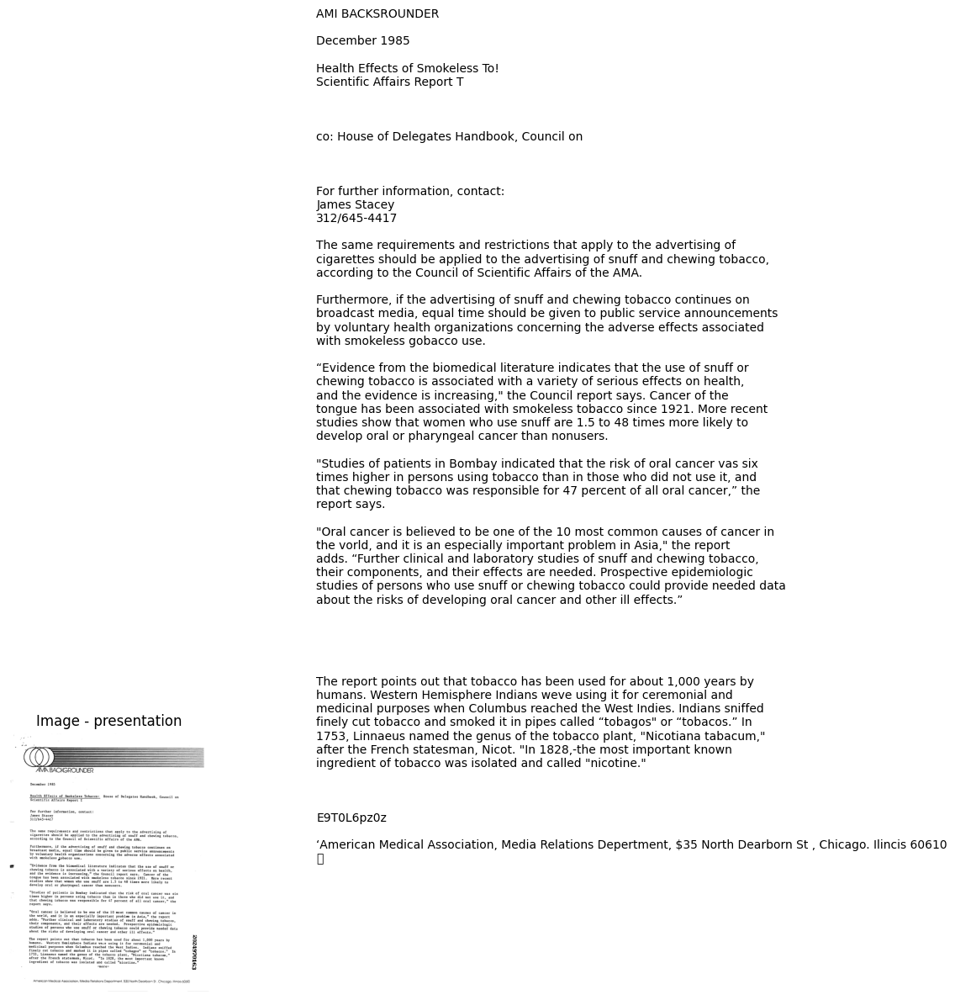

/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 12 () missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


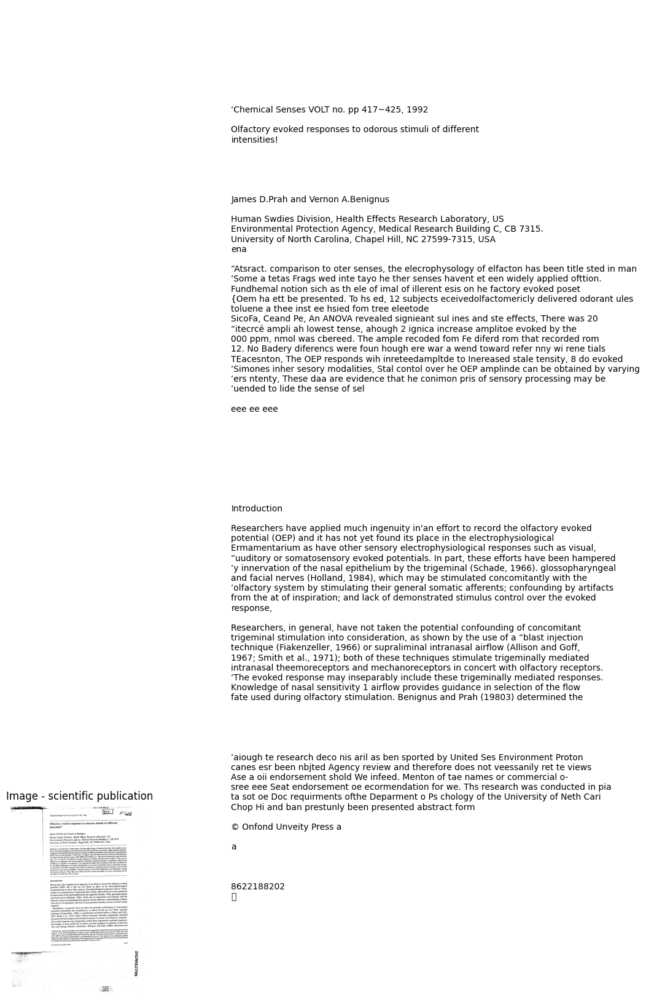

/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 12 () missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


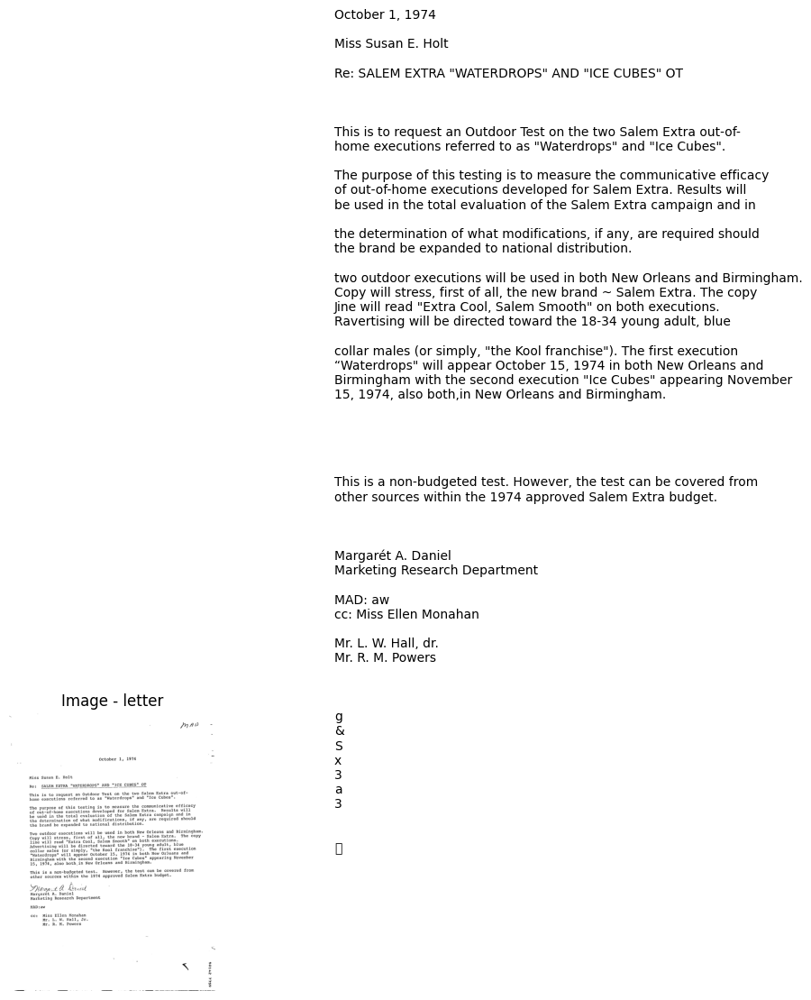

/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 12 () missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


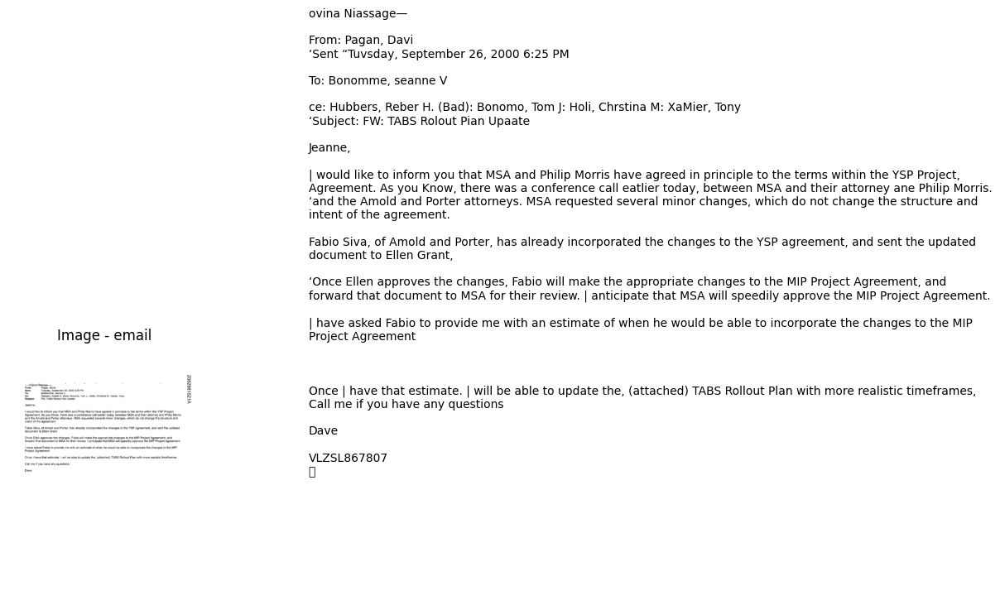

/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 12 () missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


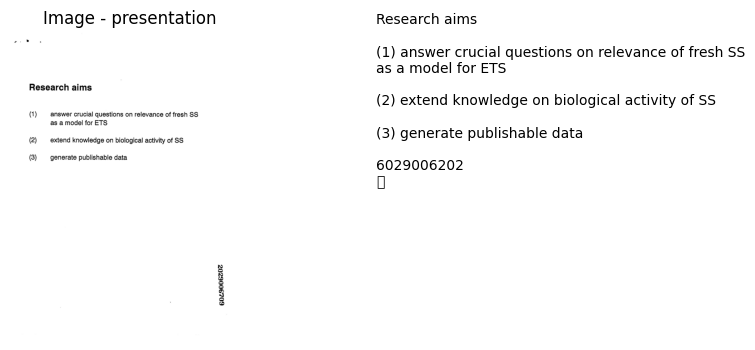

/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 12 () missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


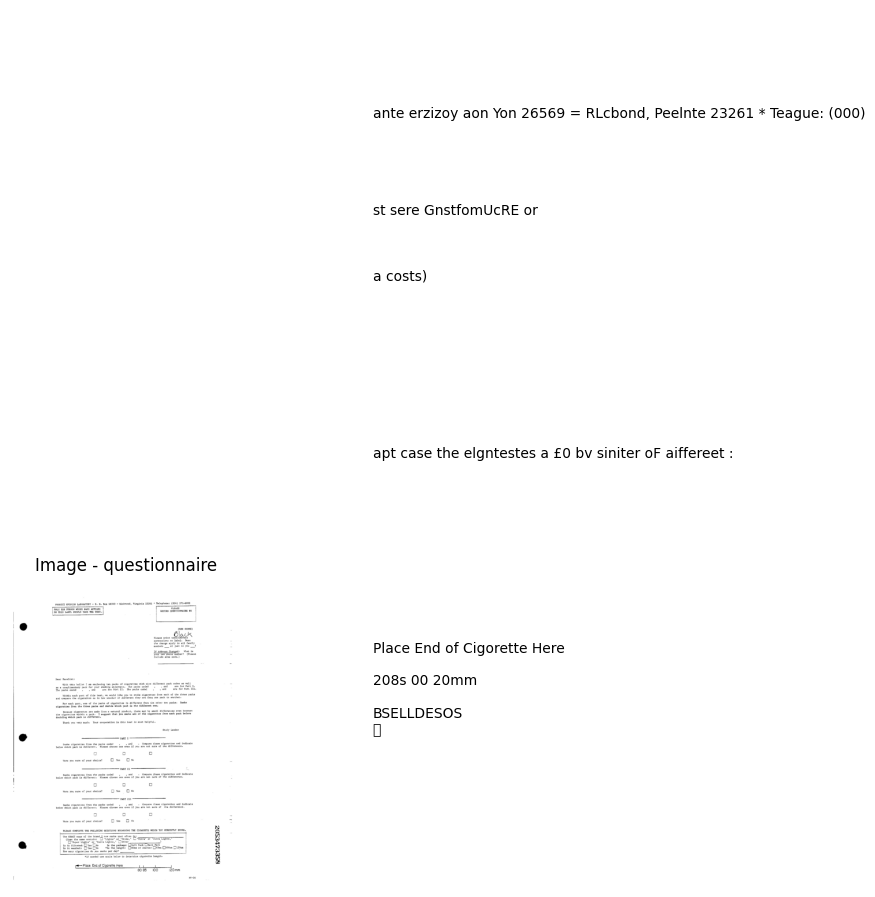

/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 12 () missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


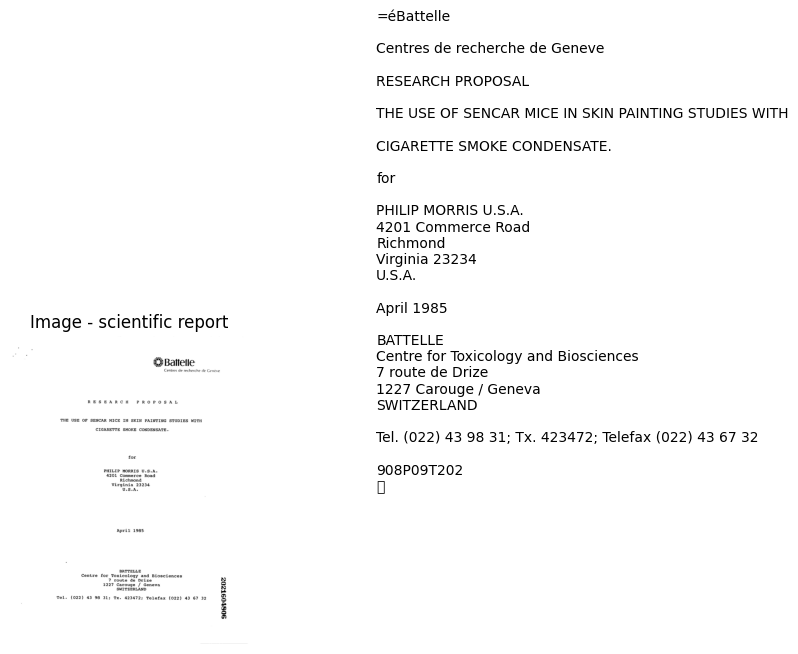

/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 12 () missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


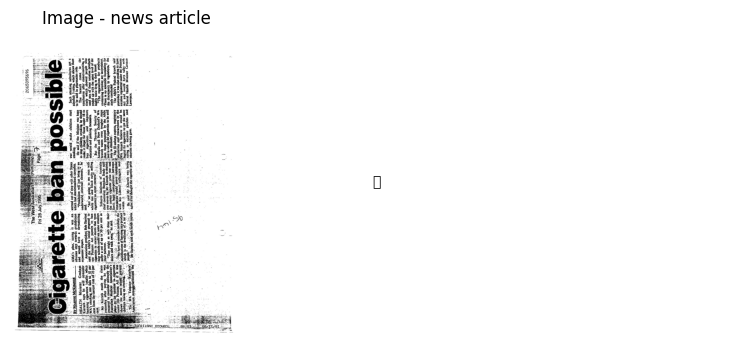

/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 12 () missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


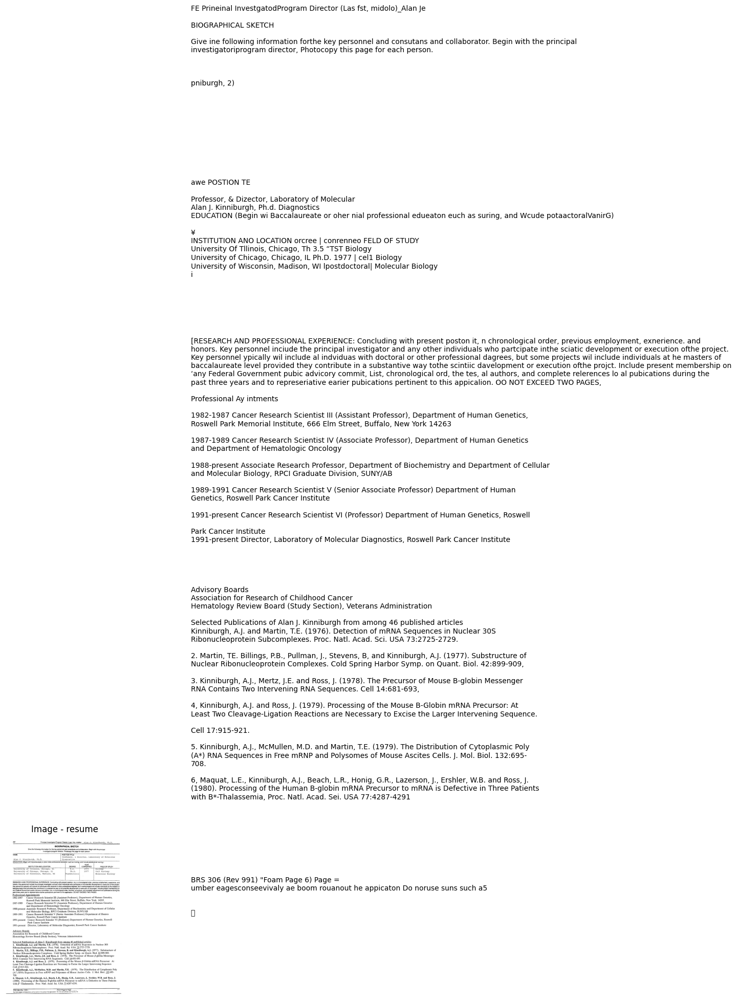

/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 12 () missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


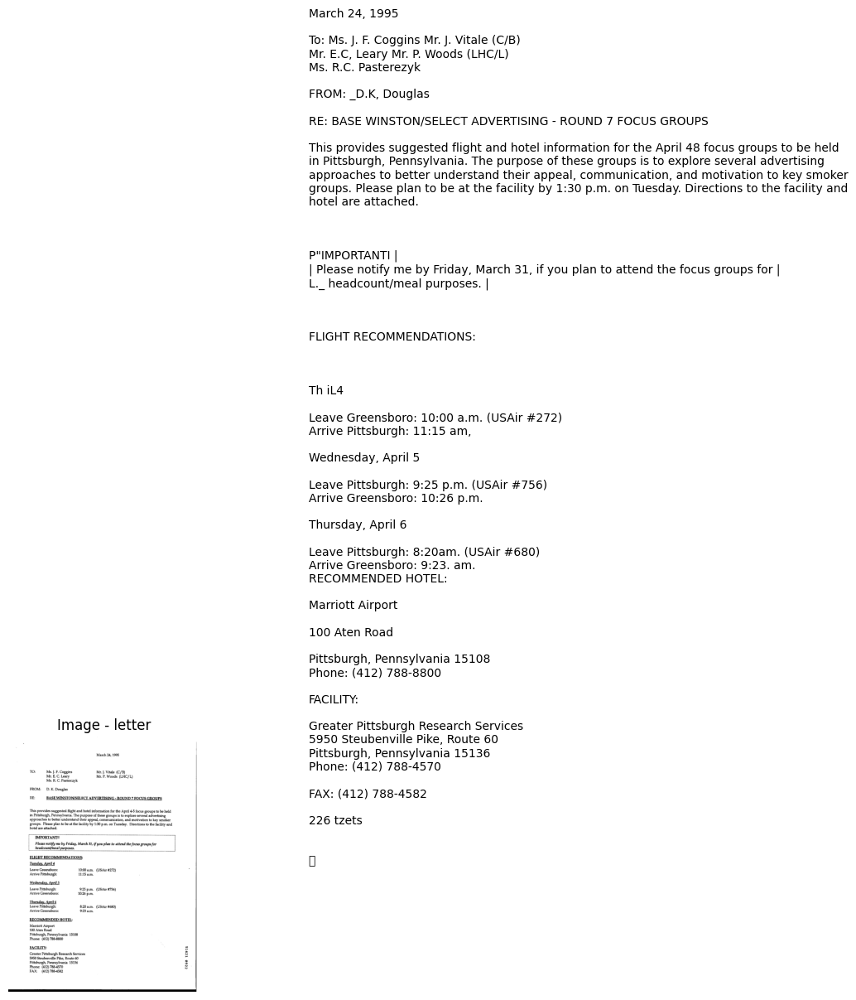

/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 12 () missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


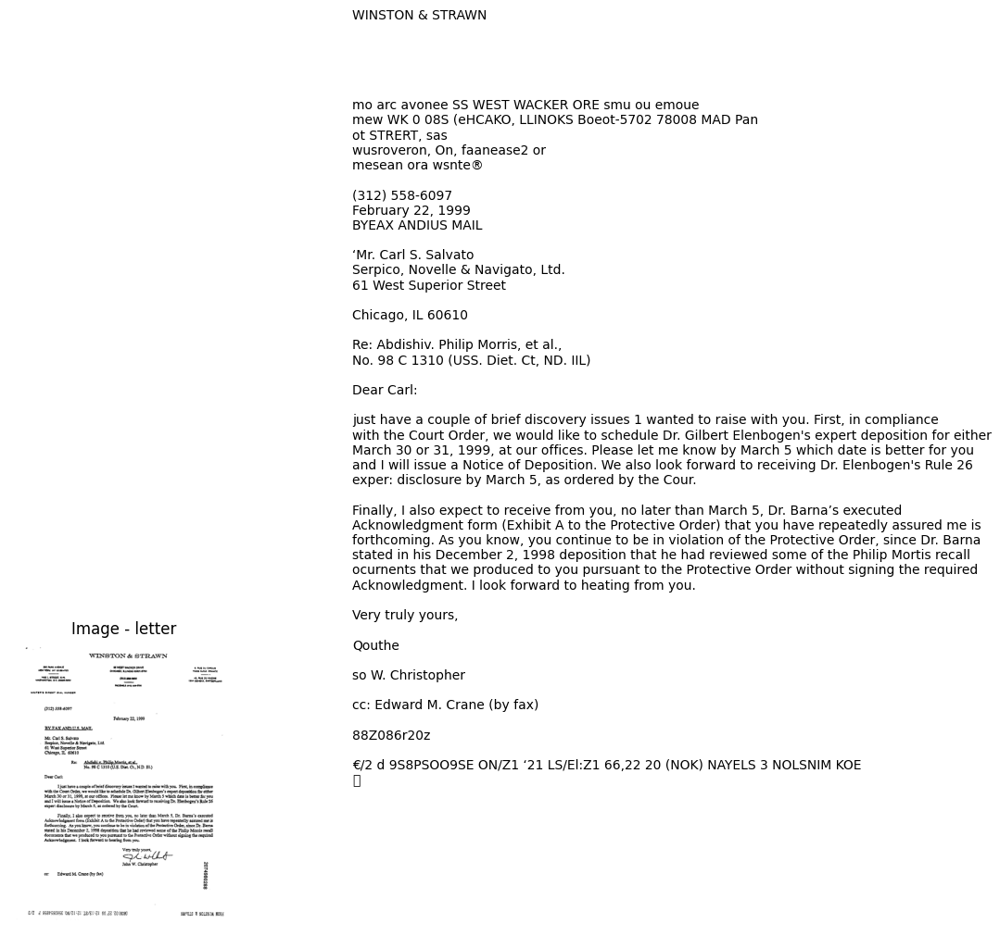

/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 12 () missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


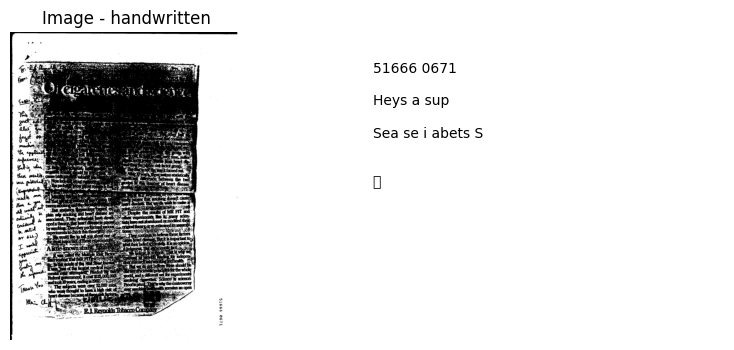

/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 12 () missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


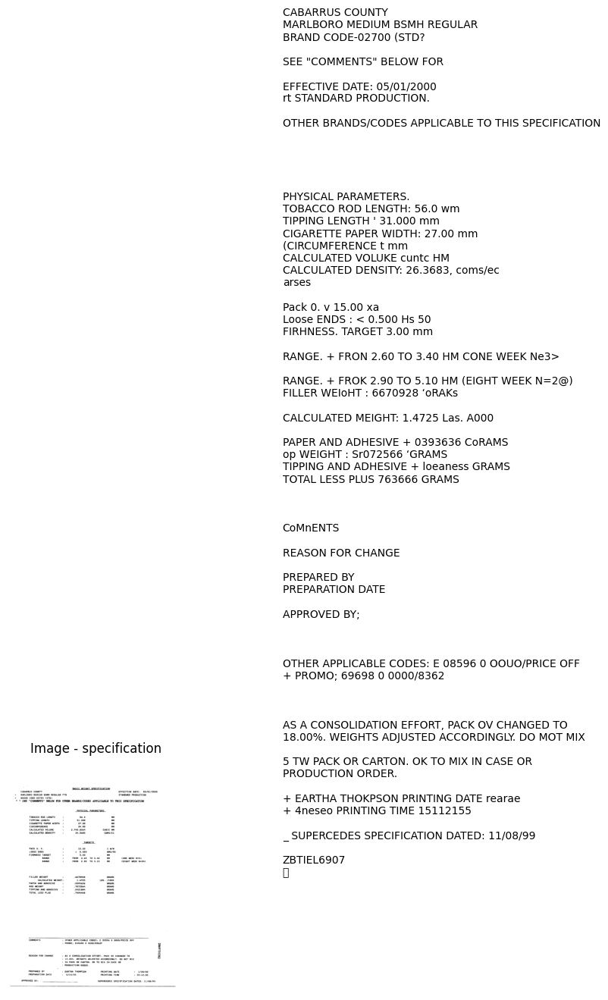

/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 12 () missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


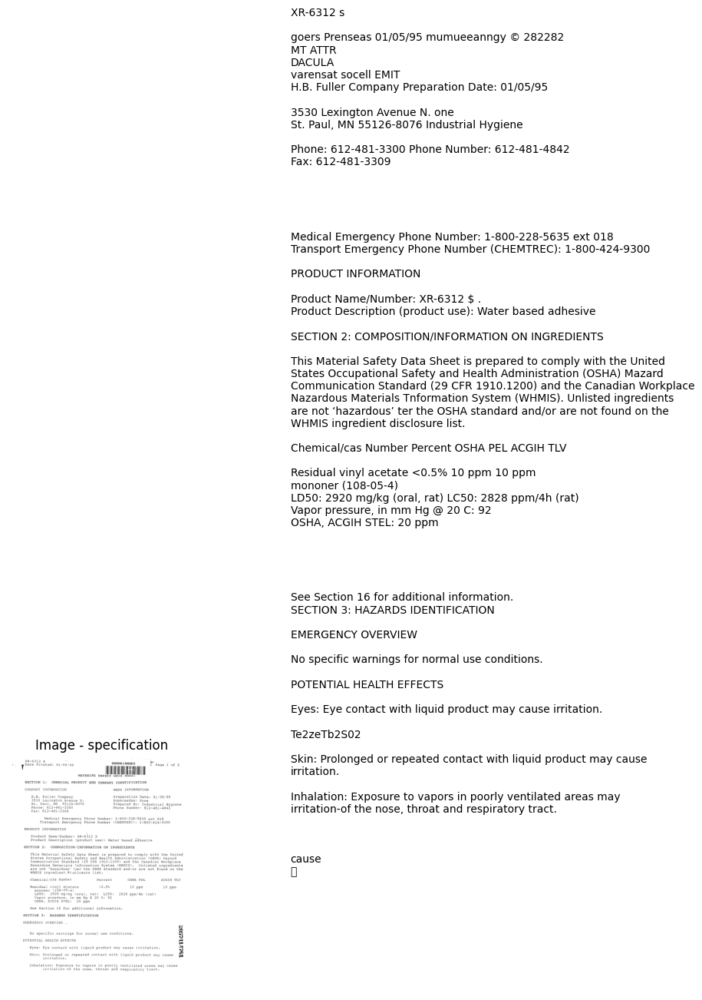

/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 12 () missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


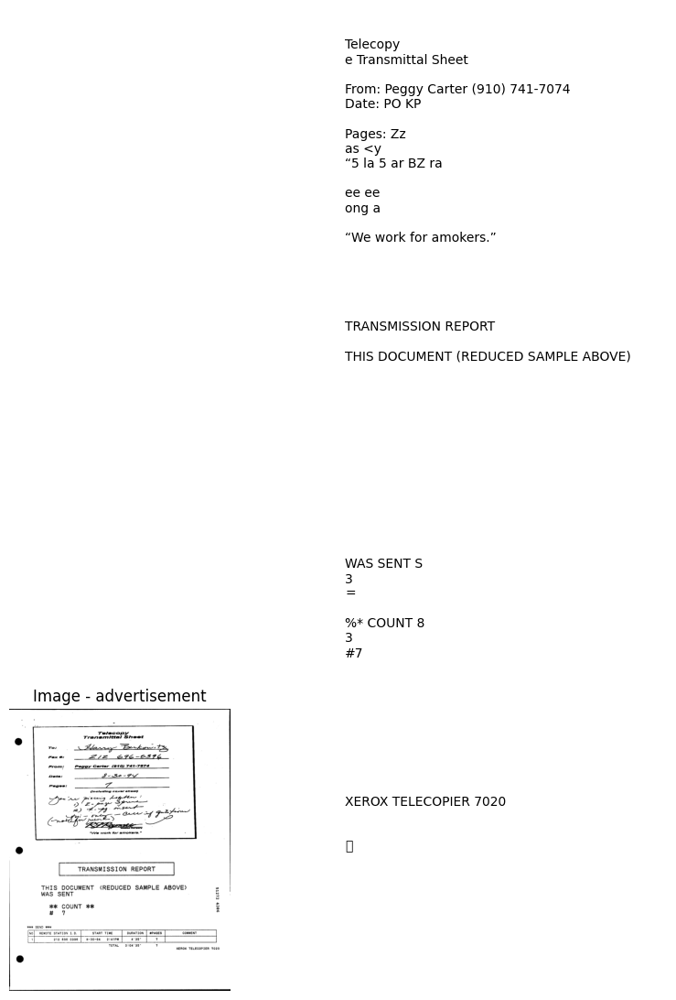

/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 12 () missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


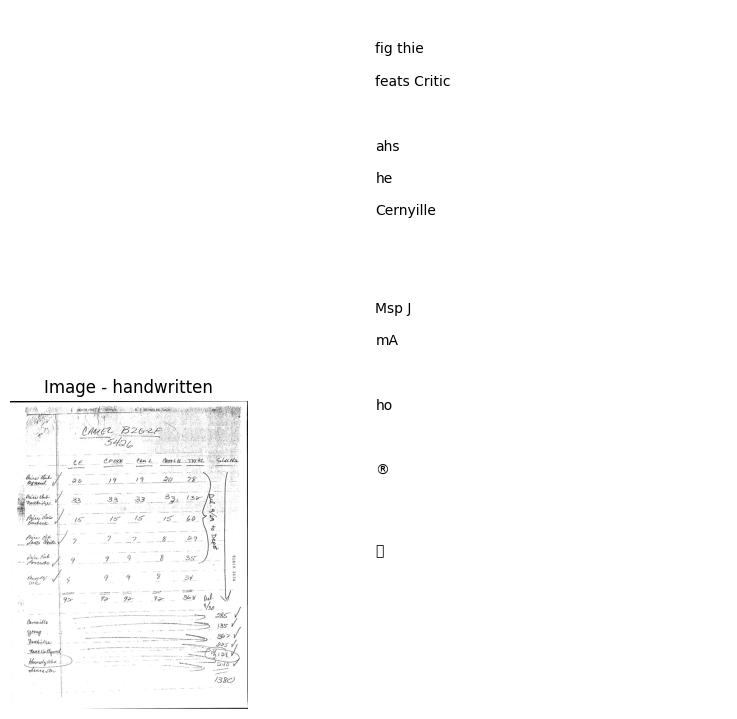

In [12]:
sample_ocr = df_rvl.sample(50, random_state=42)

results = []

for i, row in enumerate(sample_ocr.itertuples()):
    img_path = RVL_PATH / "images" / row.path
    img = Image.open(img_path).convert("RGB")

    # OCR
    text = pytesseract.image_to_string(img)

    # Affichage pour vérification humaine
    plt.figure(figsize=(10,4))

    plt.subplot(1,2,1)
    plt.imshow(img)
    plt.title(f"Image - {row.class_name}")
    plt.axis("off")

    plt.subplot(1,2,2)
    plt.text(0, 0.5, text, fontsize=10)
    plt.axis("off")

    plt.show()
    results.append({
        "class": row.class_name,
        "ocr_text": text
    })

In [13]:
duplicates_rvl = df_rvl["path"].duplicated().sum()
print("Duplicates RVL-CDIP:", duplicates_rvl)

Duplicates RVL-CDIP: 0


In [14]:
corrupted_rvl = []

sample_paths = df_rvl["path"].sample(2000, random_state=42)

for path in sample_paths:
    
    img_path = RVL_PATH / "images" / path
    
    try:
        img = Image.open(img_path)
        img.verify()
        
    except:
        corrupted_rvl.append(path)

print("Corrupted RVL images:", len(corrupted_rvl))

Corrupted RVL images: 0


DIMENSIONS DES IMAGES RVL-CDIP
📏 Largeur moyenne: 765 px
📏 Hauteur moyenne: 1000 px
📐 Largeur min/max: 611 / 845 px
📐 Hauteur min/max: 1000 / 1000 px


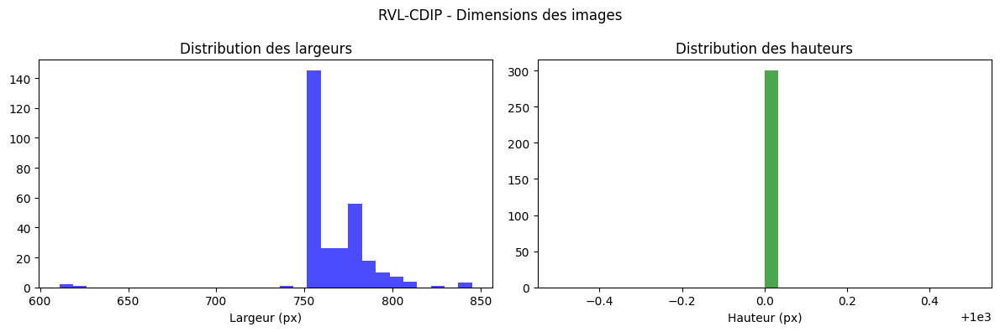

In [15]:
rvl_largeurs = []
rvl_hauteurs = []

for path in df_rvl["path"].sample(300, random_state=42):
    img = Image.open(RVL_PATH / "images" / path)
    w, h = img.size
    rvl_largeurs.append(w)
    rvl_hauteurs.append(h)

print("="*50)
print("DIMENSIONS DES IMAGES RVL-CDIP")
print("="*50)
print(f"📏 Largeur moyenne: {np.mean(rvl_largeurs):.0f} px")
print(f"📏 Hauteur moyenne: {np.mean(rvl_hauteurs):.0f} px")
print(f"📐 Largeur min/max: {min(rvl_largeurs)} / {max(rvl_largeurs)} px")
print(f"📐 Hauteur min/max: {min(rvl_hauteurs)} / {max(rvl_hauteurs)} px")

# Histogramme des dimensions
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(rvl_largeurs, bins=30, color='blue', alpha=0.7)
axes[0].set_title("Distribution des largeurs")
axes[0].set_xlabel("Largeur (px)")
axes[1].hist(rvl_hauteurs, bins=30, color='green', alpha=0.7)
axes[1].set_title("Distribution des hauteurs")
axes[1].set_xlabel("Hauteur (px)")
plt.suptitle("RVL-CDIP - Dimensions des images")
plt.tight_layout()
plt.show()

============================
MEDICAL MNIST
============================

In [16]:
classes_med = sorted([d.name for d in MED_PATH.iterdir() if d.is_dir()])
classes_med

['AbdomenCT', 'BreastMRI', 'CXR', 'ChestCT', 'Hand', 'HeadCT']

In [17]:
data = []

for c in classes_med:
    folder = MED_PATH / c
    images = list(folder.glob("*.jpeg")) 
    
    for img in images:
        data.append((str(img), c))

df_med = pd.DataFrame(data, columns=["path", "label"])
df_med.head()

,path,label
0,/kaggle/input/datasets/andrewmvd/medical-mnist...,AbdomenCT
1,/kaggle/input/datasets/andrewmvd/medical-mnist...,AbdomenCT
2,/kaggle/input/datasets/andrewmvd/medical-mnist...,AbdomenCT
3,/kaggle/input/datasets/andrewmvd/medical-mnist...,AbdomenCT
4,/kaggle/input/datasets/andrewmvd/medical-mnist...,AbdomenCT


In [18]:
df_med["label"].value_counts()

label
AbdomenCT    10000
CXR          10000
Hand         10000
ChestCT      10000
HeadCT       10000
BreastMRI     8954
Name: count, dtype: int64

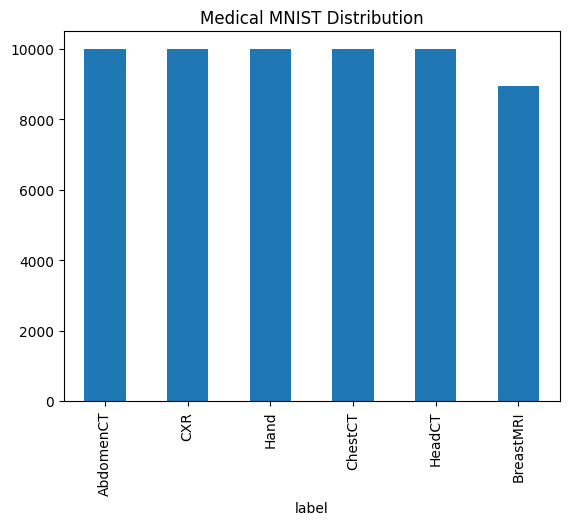

In [19]:
df_med["label"].value_counts().plot(kind="bar")
plt.title("Medical MNIST Distribution")
plt.show()

In [20]:
duplicates = df_med["path"].duplicated().sum()

print("Duplicate paths:", duplicates)

Duplicate paths: 0


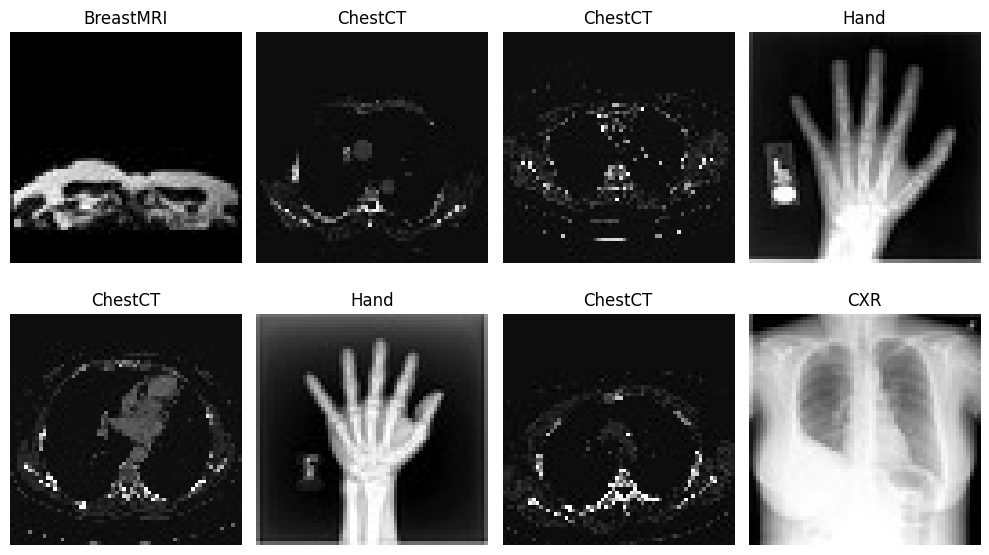

In [21]:
fig, ax = plt.subplots(2,4, figsize=(10,6))

for i in range(8):
    row = df_med.sample(1).iloc[0]
    img = Image.open(row["path"])
    
    ax[i//4,i%4].imshow(img, cmap="gray")
    ax[i//4,i%4].set_title(row["label"])
    ax[i//4,i%4].axis("off")

plt.tight_layout()
plt.show()

In [22]:
sizes = []

for p in df_med["path"].sample(300):
    img = Image.open(p)
    sizes.append(img.size)

sizes = np.array(sizes)

print("Average width:", sizes[:,0].mean())
print("Average height:", sizes[:,1].mean())

Average width: 64.0
Average height: 64.0


In [23]:
bad = []

for p in df_med["path"].sample(500):
    try:
        Image.open(p).verify()
    except:
        bad.append(p)

print("Corrupted images:", len(bad))

Corrupted images: 0


In [24]:
print("RVL-CDIP samples:", len(df_rvl))
print("Medical MNIST samples:", len(df_med))

print("RVL classes:", df_rvl["label"].nunique())
print("Medical classes:", df_med["label"].nunique())

RVL-CDIP samples: 400000
Medical MNIST samples: 58954
RVL classes: 16
Medical classes: 6


## MÉMO EDA - PHASE 1


---

### 1. DATASET RVL-CDIP

| Métrique | Valeur |
|----------|--------|
| Nombre total d'images | 320 000 |
| Nombre de classes | 16 |
| Distribution | **Parfaitement équilibrée** (25 000 images par classe) |
| Split | train/val/test (80/10/10) |
| Dimensions | Variables (moyenne ~750×1000 px) |
| OCR (n=50) | le text non lisible |
| Images corrompues | 0 |
| Doublons | 0 |
| Labels | Tous présents (0 à 15) |

**Difficultés anticipées:**
- OCR peu fiable → ne pas dépendre du texte(la qualite du l image 
- Résolutions hétérogènes → nécessite redimensionnement
- Certaines classes visuellement proches

---

### 2. DATASET MEDICAL MNIST

| Métrique | Valeur |
|----------|--------|
| Nombre total d'images | 58 954 |
| Nombre de classes | 6 |
| Distribution | Légèrement déséquilibrée |
| Dimensions | **Uniformes** (64×64 px) |
| OCR | Non applicable |
| Images corrompues | 0 |
| Doublons | 0 |

**Distribution détaillée:**
| Classe | Effectif |
|--------|----------|
| AbdomenCT | 10 000 |
| BreastMRI | 8 954 |
| CXR | 10 000 |
| ChestCT | 10 000 |
| Hand | 10 000 |
| HeadCT | 10 000 |

---


#### Branche TEXTE (RVL-CDIP) OCR+ML

In [25]:
def preprocess_image(img_path):

    img = cv2.imread(str(img_path))

    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    # denoise
    gray = cv2.fastNlMeansDenoising(gray)

    # binarization
    thresh = cv2.threshold(
        gray,
        0,
        255,
        cv2.THRESH_BINARY + cv2.THRESH_OTSU
    )[1]

    # deskew
    coords = np.column_stack(np.where(thresh > 0))

    angle = cv2.minAreaRect(coords)[-1]

    if angle < -45:
        angle = -(90 + angle)
    else:
        angle = -angle

    (h, w) = thresh.shape[:2]

    center = (w // 2, h // 2)

    M = cv2.getRotationMatrix2D(center, angle, 1.0)

    rotated = cv2.warpAffine(
        thresh,
        M,
        (w, h),
        flags=cv2.INTER_CUBIC,
        borderMode=cv2.BORDER_REPLICATE
    )

    return rotated

In [26]:
#transformez RVL-CDIP en dataset “pseudo médical”
project_mapping = {
    "letter": "lettre_liaison",

    "form": "certificat_medical",

    "email": "administratif",

    "handwritten": "consultation",

    "scientific report": "biologie",

    "scientific publication": "imagerie",

    "invoice": "administratif",

    "memo": "ordonnance",

    "specification": "autre",

    "questionnaire": "autre"
}
df_rvl["project_class"] = df_rvl["class_name"].map(project_mapping)

In [27]:
df_rvl.groupby("project_class").sum()

,path,label,split,class_name
project_class,,,,
administratif,imagesr/r/l/z/rlz20d00/521107137+-7140.tifimag...,325000,traintraintraintraintraintraintraintraintraint...,invoiceemailemailemailemailemailemailinvoicein...
autre,imagesw/w/b/t/wbt26e00/2053453161.tifimagesk/k...,500000,traintraintraintraintraintraintraintraintraint...,specificationquestionnairespecificationquestio...
biologie,imagesx/x/y/o/xyo21e00/87777221_87777238.tifim...,125000,traintraintraintraintraintraintraintraintraint...,scientific reportscientific reportscientific r...
certificat_medical,imagese/e/w/c/ewc23d00/513280028.tifimagesd/d/...,25000,traintraintraintraintraintraintraintraintraint...,formformformformformformformformformformformfo...
consultation,imageso/o/e/x/oex80d00/522787731+-7732.tifimag...,75000,traintraintraintraintraintraintraintraintraint...,handwrittenhandwrittenhandwrittenhandwrittenha...
imagerie,imagesf/f/c/s/fcs45d00/2062517421_7428.tifimag...,150000,traintraintraintraintraintraintraintraintraint...,scientific publicationscientific publicationsc...
lettre_liaison,imagesm/m/q/v/mqv03f00/0011846871.tifimagesr/r...,0,traintraintraintraintraintraintraintraintraint...,letterletterletterletterletterletterletterlett...
ordonnance,imagesq/q/o/c/qoc54c00/80035521.tifimagesc/c/u...,375000,traintraintraintraintraintraintraintraintraint...,memomemomemomemomemomemomemomemomemomemomemome...


In [28]:
SAMPLES_PER_CLASS = 2000
df_balanced = (df_rvl.groupby("project_class").apply(lambda x: x.sample(min(len(x), SAMPLES_PER_CLASS), random_state=42)).reset_index(drop=True))

/tmp/ipykernel_57/3687485144.py:2: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  df_balanced = (df_rvl.groupby("project_class").apply(lambda x: x.sample(min(len(x), SAMPLES_PER_CLASS), random_state=42)).reset_index(drop=True))


In [29]:
df_balanced.groupby("project_class").sum()

,path,label,split,class_name
project_class,,,,
administratif,imagesj/j/u/j/juj25a00/528850775+-0776.tifimag...,13162,traintraintraintraintrainvaltraintesttraintrai...,emailemailemailemailemailinvoiceemailemailinvo...
autre,imagesu/u/u/y/uuy54c00/87595974.tifimagesv/v/c...,19718,traintraintraintraintrainvaltraintesttraintrai...,questionnairespecificationquestionnairequestio...
biologie,imagesw/w/l/r/wlr23c00/96811762_1785.tifimages...,10000,traintesttraintraintraintraintraintraintraintr...,scientific reportscientific reportscientific r...
certificat_medical,imagesw/w/c/i/wci45a00/509103250+-3250.tifimag...,2000,traintesttraintraintraintraintraintraintraintr...,formformformformformformformformformformformfo...
consultation,imagesk/k/l/c/klc43d00/512185889_512185890.tif...,6000,traintesttraintraintraintraintraintraintraintr...,handwrittenhandwrittenhandwrittenhandwrittenha...
imagerie,imagesq/q/b/u/qbu06d00/50526219-6233.tifimages...,12000,traintesttraintraintraintraintraintraintraintr...,scientific publicationscientific publicationsc...
lettre_liaison,imagese/e/o/c/eoc03a00/518597182+-7182.tifimag...,0,traintesttraintraintraintraintraintraintraintr...,letterletterletterletterletterletterletterlett...
ordonnance,imagesr/r/k/c/rkc71e00/03721309_03721310.tifim...,30000,traintesttraintraintraintraintraintraintraintr...,memomemomemomemomemomemomemomemomemomemomemome...


<Axes: xlabel='project_class'>

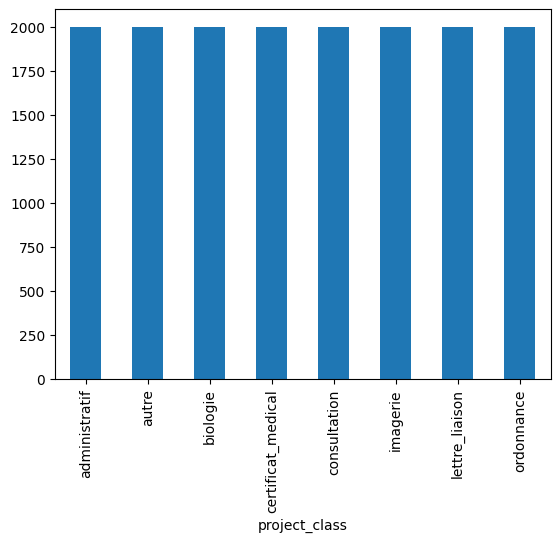

In [30]:
df_balanced["project_class"].value_counts().plot(kind="bar")

In [31]:
sample_compare = df_balanced.sample(100, random_state=42)
reader = easyocr.Reader(['en'], gpu=False)
results_compare = []

for row in tqdm(sample_compare.itertuples(), total=100):
    img_path = RVL_PATH / "images" / row.path
    processed = preprocess_image(img_path)
    # TESSERACT
    start = time.time()
    text_tess = pytesseract.image_to_string(processed)
    time_tess = time.time() - start
    # EASYOCR
    start = time.time()
    text_easy = reader.readtext(processed, detail=0)
    text_easy = " ".join(text_easy)
    time_easy = time.time() - start
    results_compare.append({
        "class": row.class_name,
        "tesseract_len": len(text_tess),
        "easyocr_len": len(text_easy),
        "tesseract_time": time_tess,
        "easyocr_time": time_easy
    })
compare_df = pd.DataFrame(results_compare)
compare_df.head()

Using CPU. Note: This module is much faster with a GPU.


  0%|          | 0/100 [00:00<?, ?it/s]

,class,tesseract_len,easyocr_len,tesseract_time,easyocr_time
0,handwritten,23,25,0.173784,5.801550
1,scientific report,1840,1782,1.467350,8.960989
2,form,904,826,0.940187,7.995798
3,invoice,460,573,0.624351,7.524003
4,handwritten,30,274,0.196481,6.442918


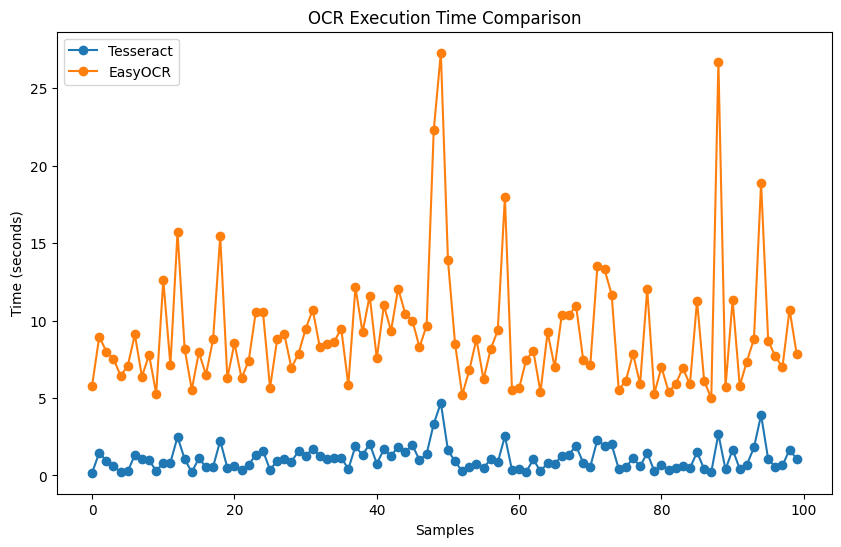

In [32]:
plt.figure(figsize=(10,6))

plt.plot(compare_df["tesseract_time"], label="Tesseract", marker="o")
plt.plot(compare_df["easyocr_time"], label="EasyOCR", marker="o")

plt.title("OCR Execution Time Comparison")
plt.xlabel("Samples")
plt.ylabel("Time (seconds)")
plt.legend()

plt.show()

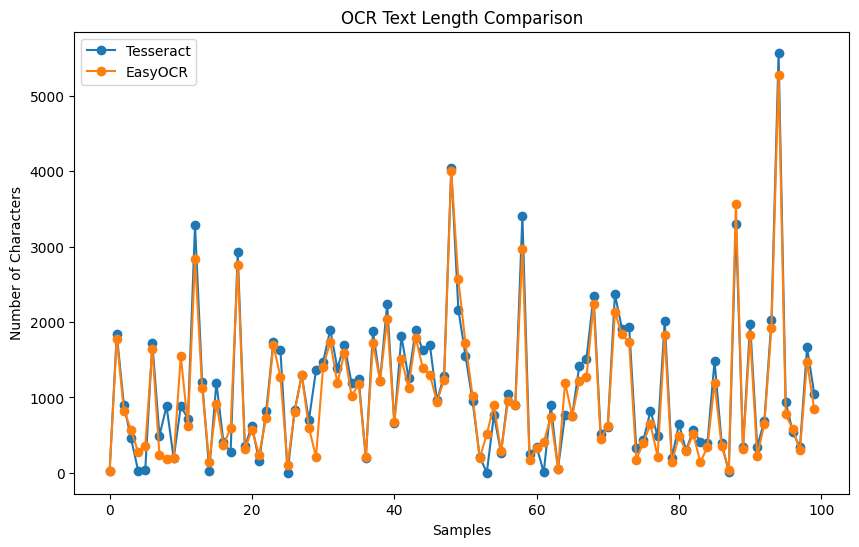

In [33]:
plt.figure(figsize=(10,6))

plt.plot(compare_df["tesseract_len"], label="Tesseract", marker="o")
plt.plot(compare_df["easyocr_len"], label="EasyOCR", marker="o")

plt.title("OCR Text Length Comparison")
plt.xlabel("Samples")
plt.ylabel("Number of Characters")
plt.legend()

plt.show()

Nous avons choisi Tesseract OCR pour ce projet car il est nettement plus rapide qu’EasyOCR tout en offrant une qualité d’extraction comparable.

In [34]:
"""import pandas as pd
import os
csv_path = "/kaggle/working/ocr_results.csv"
if os.path.exists(csv_path):
    df_results = pd.read_csv(csv_path)
    processed_set = set(df_results["image_path"])
    print("deja cree")
else:
    df_results = pd.DataFrame(columns=["image_path", "text"])
    print("bien cree")
    df_results.to_csv(csv_path, index=False)
    processed_set = set()"""

'import pandas as pd\nimport os\ncsv_path = "/kaggle/working/ocr_results.csv"\nif os.path.exists(csv_path):\n    df_results = pd.read_csv(csv_path)\n    processed_set = set(df_results["image_path"])\n    print("deja cree")\nelse:\n    df_results = pd.DataFrame(columns=["image_path", "text"])\n    print("bien cree")\n    df_results.to_csv(csv_path, index=False)\n    processed_set = set()'

In [35]:
"""results =[]
for _, row in df_results.iterrows():

    results.append({
        "image_path": row["image_path"],
        "text": row["text"]
    })
len(results)"""

'results =[]\nfor _, row in df_results.iterrows():\n\n    results.append({\n        "image_path": row["image_path"],\n        "text": row["text"]\n    })\nlen(results)'

In [36]:
"""batch_size = 1000
processed_set = set(df_results["image_path"])
for i, img_path in tqdm(enumerate(df_balanced["path"].values)):
    if img_path in processed_set:
        continue
    img = RVL_PATH / "images" / img_path
    processed_img = preprocess_image(img)
    text = pytesseract.image_to_string(processed_img)
    results.append({
        "image_path": img_path,
        "text": text
    })
    if len(results) % batch_size == 0:
        pd.DataFrame(results).to_csv(csv_path)"""

'batch_size = 1000\nprocessed_set = set(df_results["image_path"])\nfor i, img_path in tqdm(enumerate(df_balanced["path"].values)):\n    if img_path in processed_set:\n        continue\n    img = RVL_PATH / "images" / img_path\n    processed_img = preprocess_image(img)\n    text = pytesseract.image_to_string(processed_img)\n    results.append({\n        "image_path": img_path,\n        "text": text\n    })\n    if len(results) % batch_size == 0:\n        pd.DataFrame(results).to_csv(csv_path)'

In [37]:
csv_path = "/kaggle/input/datasets/hibachach/result-ocr/ocr_results (6).csv"
df_ocr = pd.read_csv(csv_path)
df_ocr

,Unnamed: 0,image_path,text
0,0,imagesj/j/u/j/juj25a00/528850775+-0776.tif,52885 0775\n\n \n\n \n\n \n\n \n\n \n\n \n\n \...
1,1,imagesy/y/h/k/yhk36c00/2078311626.tif,"2078311628:\n\n \n\nTo: Ci ) Mary; Cexcazo,..."
2,2,imagest/t/k/z/tkz16c00/2083319124.tif,\n\nhow's Friday at 4:007\n\nCarolyn Lewy\nYo...
3,3,imagesl/l/r/f/lrf20c00/2085785866.tif,"2085785866\n\nPabst, Joanne\n\nFrom: Beriind, ..."
4,4,imagesh/h/k/w/hkw72a00/528015544+-5544.tif,"From: Osmon, Greg\nTo: Smith, Mark D.\nce:\nBC..."
...,...,...,...
15995,15995,imagesq/q/e/e/qee87e00/2504062214.tif,"\n\nPHILIP MORRIS INTERNATIONALING, __ INTER-..."
15996,15996,imagese/e/e/h/eeh36e00/2046262296.tif,BHILIP MORRIS MANAGEMENT CORP. INTER-OFFICE CO...
15997,15997,imagesl/l/c/a/lca35f00/0060219178.tif,\n\n \n\nTHE As Memorandum\n= AMERICAN ” t\nf...
15998,15998,imagesy/y/g/x/ygx32e00/2504011052.tif,te\n\nobec:\n\n“PHILIP MORRIS ASIA INCORPORATE...


In [38]:
project_mapping = {
    "lettre_liaison":  1,

    "certificat_medical": 2,

    "administratif": 3,

     "consultation": 4,

     "biologie": 5,

    "imagerie": 6,

     "ordonnance": 7,

    "autre": 8,
}
df_rvl["label_2"] = df_rvl["project_class"].map(project_mapping)
df_rvl["label_2"] 

0         7.0
1         2.0
2         8.0
3         NaN
4         4.0
         ... 
399995    7.0
399996    NaN
399997    NaN
399998    3.0
399999    NaN
Name: label_2, Length: 400000, dtype: float64

In [39]:
df_labels = df_rvl[["path", "label_2", "split"]]
df_final = df_ocr.merge(
    df_labels,
    left_on="image_path",
    right_on="path"
)
df_final.shape

(16000, 6)

In [40]:
df_final=df_final.drop_duplicates(subset="path")

In [41]:
df_final.dropna(subset="text")

,Unnamed: 0,image_path,text,path,label_2,split
0,0,imagesj/j/u/j/juj25a00/528850775+-0776.tif,52885 0775\n\n \n\n \n\n \n\n \n\n \n\n \n\n \...,imagesj/j/u/j/juj25a00/528850775+-0776.tif,3.0,train
1,1,imagesy/y/h/k/yhk36c00/2078311626.tif,"2078311628:\n\n \n\nTo: Ci ) Mary; Cexcazo,...",imagesy/y/h/k/yhk36c00/2078311626.tif,3.0,train
2,2,imagest/t/k/z/tkz16c00/2083319124.tif,\n\nhow's Friday at 4:007\n\nCarolyn Lewy\nYo...,imagest/t/k/z/tkz16c00/2083319124.tif,3.0,train
3,3,imagesl/l/r/f/lrf20c00/2085785866.tif,"2085785866\n\nPabst, Joanne\n\nFrom: Beriind, ...",imagesl/l/r/f/lrf20c00/2085785866.tif,3.0,train
4,4,imagesh/h/k/w/hkw72a00/528015544+-5544.tif,"From: Osmon, Greg\nTo: Smith, Mark D.\nce:\nBC...",imagesh/h/k/w/hkw72a00/528015544+-5544.tif,3.0,train
...,...,...,...,...,...,...
15995,15995,imagesq/q/e/e/qee87e00/2504062214.tif,"\n\nPHILIP MORRIS INTERNATIONALING, __ INTER-...",imagesq/q/e/e/qee87e00/2504062214.tif,7.0,train
15996,15996,imagese/e/e/h/eeh36e00/2046262296.tif,BHILIP MORRIS MANAGEMENT CORP. INTER-OFFICE CO...,imagese/e/e/h/eeh36e00/2046262296.tif,7.0,test
15997,15997,imagesl/l/c/a/lca35f00/0060219178.tif,\n\n \n\nTHE As Memorandum\n= AMERICAN ” t\nf...,imagesl/l/c/a/lca35f00/0060219178.tif,7.0,train
15998,15998,imagesy/y/g/x/ygx32e00/2504011052.tif,te\n\nobec:\n\n“PHILIP MORRIS ASIA INCORPORATE...,imagesy/y/g/x/ygx32e00/2504011052.tif,7.0,train


In [42]:
import re

def clean_text(text):

    text = str(text).lower()

    text = re.sub(r"[^a-zA-Z0-9\s]", " ", text)

    text = " ".join(text.split())

    return text

df_final["clean_text"] = df_final["text"].apply(clean_text)

In [43]:
X_train, X_test, y_train, y_test = train_test_split(
    df_final["clean_text"],
    df_final["label_2"],
    test_size=0.2,
    stratify=df_final["label_2"],
    random_state=42
)
print(X_train.shape)
print(X_test.shape)

(12776,)
(3195,)


In [44]:
#Pipelines
pipeline_lr = Pipeline([
    ("tfidf", TfidfVectorizer(stop_words="english")),
    ("clf", LogisticRegression(max_iter=1000))
])
pipeline_svm = Pipeline([
    ("tfidf", TfidfVectorizer(stop_words="english")),
    ("clf", LinearSVC())
])

In [45]:
param_grid_lr = {
    "tfidf__max_features": [5000, 10000],
    "tfidf__ngram_range": [(1,1), (1,2)],
    "clf__C": [0.1, 1, 10]
}

param_grid_svm = {
    "tfidf__max_features": [5000, 10000],
    "tfidf__ngram_range": [(1,1), (1,2)],
    "clf__C": [0.1, 1, 10]
}

In [46]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

In [47]:
from sklearn.model_selection import GridSearchCV
grid_lr = GridSearchCV(
    pipeline_lr,
    param_grid_lr,
    cv=cv,
    scoring="f1_macro",
    n_jobs=-1,
    verbose=2
)

grid_lr.fit(X_train, y_train)

Fitting 5 folds for each of 12 candidates, totalling 60 fits


GridSearchCV(cv=StratifiedKFold(n_splits=5, random_state=42, shuffle=True),
             estimator=Pipeline(steps=[('tfidf',
                                        TfidfVectorizer(stop_words='english')),
                                       ('clf',
                                        LogisticRegression(max_iter=1000))]),
             n_jobs=-1,
             param_grid={'clf__C': [0.1, 1, 10],
                         'tfidf__max_features': [5000, 10000],
                         'tfidf__ngram_range': [(1, 1), (1, 2)]},
             scoring='f1_macro', verbose=2)

In [48]:

grid_svm = GridSearchCV(
    pipeline_svm,
    param_grid_svm,
    cv=cv,
    scoring="f1_macro",
    n_jobs=-1,
    verbose=2
)

grid_svm.fit(X_train, y_train)

Fitting 5 folds for each of 12 candidates, totalling 60 fits


GridSearchCV(cv=StratifiedKFold(n_splits=5, random_state=42, shuffle=True),
             estimator=Pipeline(steps=[('tfidf',
                                        TfidfVectorizer(stop_words='english')),
                                       ('clf', LinearSVC())]),
             n_jobs=-1,
             param_grid={'clf__C': [0.1, 1, 10],
                         'tfidf__max_features': [5000, 10000],
                         'tfidf__ngram_range': [(1, 1), (1, 2)]},
             scoring='f1_macro', verbose=2)

In [49]:
print(" Best LR params:", grid_lr.best_params_)
print("Best LR CV score:", grid_lr.best_score_)

print(" Best SVM params:", grid_svm.best_params_)
print(" Best SVM CV score:", grid_svm.best_score_)

 Best LR params: {'clf__C': 10, 'tfidf__max_features': 10000, 'tfidf__ngram_range': (1, 2)}
Best LR CV score: 0.7442813452137644
 Best SVM params: {'clf__C': 0.1, 'tfidf__max_features': 10000, 'tfidf__ngram_range': (1, 2)}
 Best SVM CV score: 0.7406178014936374


In [50]:
def evaluate_model(model, X_test, y_test, class_names=None, title="Model"):
    
    # =====================
    #  prédictions
    # =====================
    y_pred = model.predict(X_test)
    
    # =====================
    #  Accuracy + F1 macro
    # =====================
    acc = accuracy_score(y_test, y_pred)
    f1_macro = f1_score(y_test, y_pred, average="macro")
    
    print(f"\n===== {title} =====")
    print(f"Accuracy  : {acc:.4f}")
    print(f"F1 Macro  : {f1_macro:.4f}")
    
    # =====================
    #  F1 par classe
    # =====================
    print("\nClassification Report:\n")
    print(classification_report(y_test, y_pred))
    
    # =====================
    # Matrice de confusion
    # =====================
    cm = confusion_matrix(y_test, y_pred)
    
    plt.figure(figsize=(6,5))
    plt.imshow(cm, cmap="Blues")
    plt.title(f"Confusion Matrix - {title}")
    plt.colorbar()
    plt.xlabel("Predicted")
    plt.ylabel("True")
    plt.xticks(range(len(cm)), class_names, rotation=45)
    plt.yticks(range(len(cm)), class_names)
    plt.show()
    
    # =====================
    #  Precision / Recall curves
    # =====================
    
    # important pour SVM / LR : decision_function
    if hasattr(model, "decision_function"):
        y_score = model.decision_function(X_test)
    else:
        y_score = model.predict_proba(X_test)
    
    classes = np.unique(y_test)
    
    plt.figure(figsize=(7,5))
    
    for i, cls in enumerate(classes):
        y_binary = (y_test == cls).astype(int)
        
        scores = y_score[:, i] if len(classes) > 2 else y_score
        
        precision, recall, _ = precision_recall_curve(y_binary, scores)
        
        plt.plot(recall, precision, label=f"Class {cls}")
    
    plt.title(f"Precision-Recall Curves - {title}")
    plt.xlabel("Recall")
    plt.ylabel("Precision")
    plt.legend()
    plt.grid()
    plt.show()


===== Logistic Regression =====
Accuracy  : 0.7393
F1 Macro  : 0.7387

Classification Report:

              precision    recall  f1-score   support

         1.0       0.77      0.68      0.72       400
         2.0       0.73      0.62      0.67       400
         3.0       0.79      0.77      0.78       400
         4.0       0.63      0.85      0.72       400
         5.0       0.67      0.63      0.65       400
         6.0       0.85      0.85      0.85       400
         7.0       0.72      0.74      0.73       395
         8.0       0.79      0.77      0.78       400

    accuracy                           0.74      3195
   macro avg       0.74      0.74      0.74      3195
weighted avg       0.74      0.74      0.74      3195



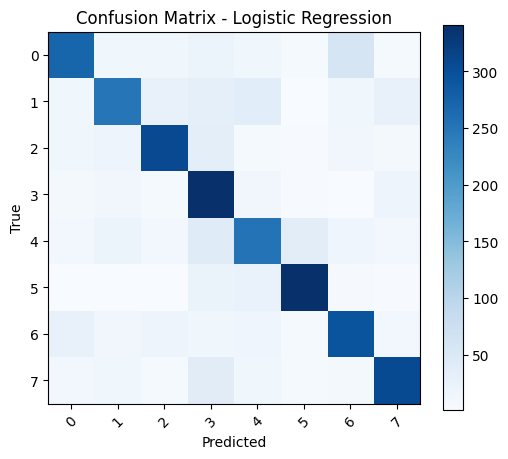

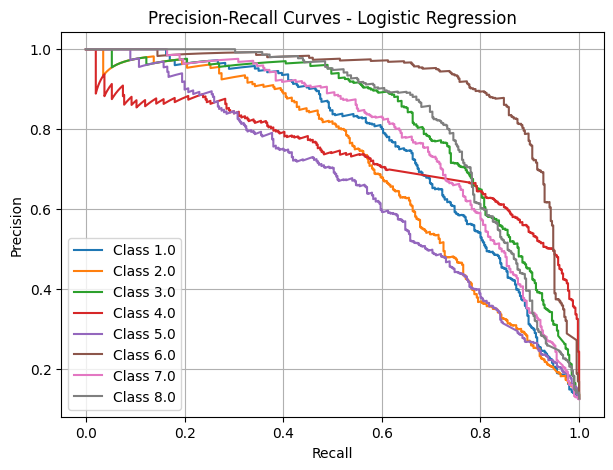

In [51]:
best_lr = grid_lr.best_estimator_

evaluate_model(
    best_lr,
    X_test,
    y_test,
    title="Logistic Regression"
)


===== Linear SVM =====
Accuracy  : 0.7399
F1 Macro  : 0.7396

Classification Report:

              precision    recall  f1-score   support

         1.0       0.78      0.67      0.72       400
         2.0       0.79      0.61      0.69       400
         3.0       0.84      0.79      0.81       400
         4.0       0.57      0.93      0.70       400
         5.0       0.71      0.60      0.65       400
         6.0       0.79      0.88      0.83       400
         7.0       0.73      0.73      0.73       395
         8.0       0.85      0.73      0.79       400

    accuracy                           0.74      3195
   macro avg       0.76      0.74      0.74      3195
weighted avg       0.76      0.74      0.74      3195



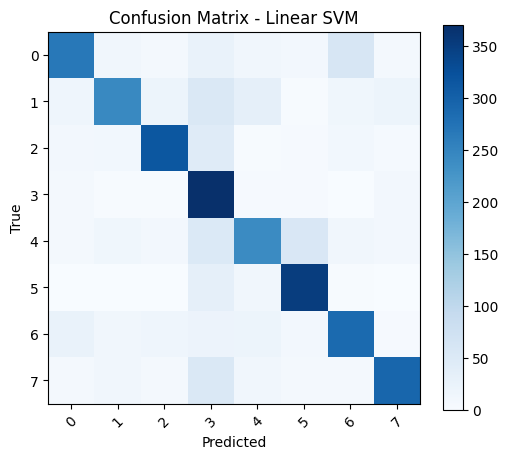

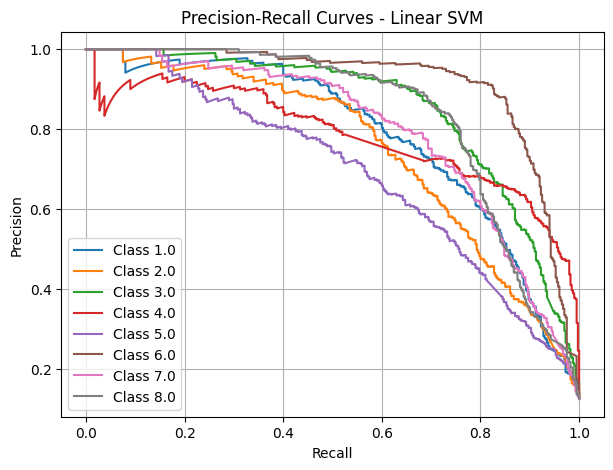

In [52]:
best_svm = grid_svm.best_estimator_

evaluate_model(
    best_svm,
    X_test,
    y_test,
    title="Linear SVM"
)

In [53]:
joblib.dump(
    best_svm ,
    "baseline_tfidf_svm.joblib"
)

['baseline_tfidf_svm.joblib']

In [55]:
y_pred = best_svm.predict(X_test)

# dataframe erreurs
errors_df = pd.DataFrame({
    "text": X_test,
    "true_label": y_test,
    "pred_label": y_pred
})

# garder seulement erreurs
errors_df = errors_df[
    errors_df["true_label"] != errors_df["pred_label"]
]

print("Nombre erreurs :", len(errors_df))

# voir premières erreurs
errors_df.head(10)

Nombre erreurs : 831


,text,true_label,pred_label
3876,cemenen ample spleoficationspilot plant mork r...,8.0,4.0
3537,cry february 21 1977 questionnaire rs soresta ...,8.0,6.0
13350,bio research consultants inc consunation risea...,1.0,5.0
3286,mrvowen srr oy gecocurrron seman fpodbvetion g...,8.0,2.0
7985,to today s wale 3 20 78 me flinn me donahue lo...,2.0,1.0
13665,ajr inter office memorandum e ugust 3 1907 to ...,1.0,5.0
12435,secr addressee only no a77 by subject analyais...,1.0,7.0
192,06 31am est 21 006 00 bometein pacorslo bil 21...,3.0,6.0
9421,tasle ty a one tur ant three like modelo br bl...,4.0,5.0
11372,jhinou aptod oa sopnaepes mun poet psn tmp er ...,6.0,4.0


In [63]:
inverse_mapping = {
    1:"lettre_liaison",
    2:"certificat_medical",
    3:"administratif",
    4:"consultation",
    5:"biologie",
    6:"imagerie",
    7:"ordonnance",
    8:"autre"
}

errors_df["true_name"] = errors_df["true_label"].map(inverse_mapping)
errors_df["pred_name"] = errors_df["pred_label"].map(inverse_mapping)

In [64]:
for i in range(20):

    row = errors_df.iloc[i]

    print("="*80)

    print("VRAI :", row["true_name"])
    print("PREDIT :", row["pred_name"])

    print("\nTEXT OCR :\n")
    print(row["text"][:1500])

    print("\n")

VRAI : autre
PREDIT : consultation

TEXT OCR :

cemenen ample spleoficationspilot plant mork request mile nen seem kes er serena melee a ae tae 0 wen sten bes ep ege 4 fuae on et enon ovr caawn wn hr an frameoroetaa pere een site pts ms toore ope ot enseeue yn e beu tg ee q s a s 2 2


VRAI : autre
PREDIT : imagerie

TEXT OCR :

cry february 21 1977 questionnaire rs soresta smoke study group yes sie 2 aemeae i would be interested in participating ina new task force as indicated below also please rate projects 1 being highest in your opinion 2 next to highest and so on oxides of witrogen in smoke volatile aldehydes in smoke pa ai 2 pe of smoke 7 7 chemistry of side stream smoke fa a i wt effect of air ventilation of cigarette 7 filters b ae ss effects of style of smoking in j a zt mechanical smoking machines le os vee 9 ag ith technol re tt 38 joint task force with technology group subject to be determined f sit in munich in september 1977 a 8 a joint task force with agronomy group ei a

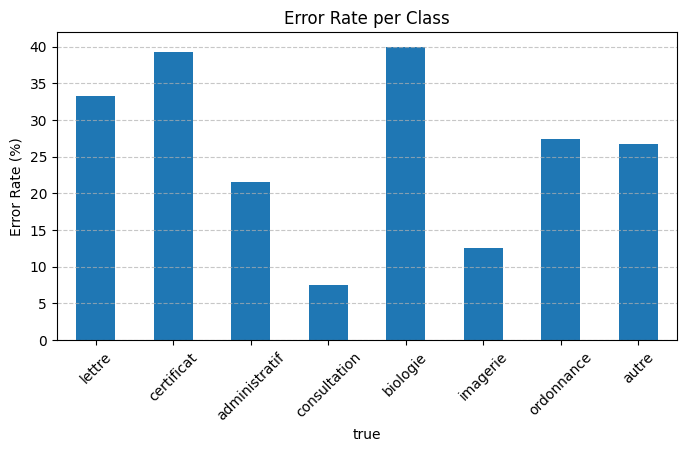

In [68]:
labels = [
    "lettre",
    "certificat",
    "administratif",
    "consultation",
    "biologie",
    "imagerie",
    "ordonnance",
    "autre"
]

total = errors.groupby("true").size()

error_rate = (
    error_count / total
) * 100

plt.figure(figsize=(8,4))

error_rate.plot(
    kind="bar"
)

plt.ylabel("Error Rate (%)")

plt.title(
    "Error Rate per Class"
)

plt.xticks(
    range(len(labels)),
    labels,
    rotation=45
)

plt.grid(
    axis="y",
    linestyle="--",
    alpha=0.7
)

plt.show()

# Analyse du Taux d'Erreur par Classe - Modèle Baseline

## Vue d'ensemble

Ce graphique présente le **taux d'erreur par classe** pour le modèle baseline TF-IDF +  SVM. Les performances sont très inégales entre les classes, variant de **8% (Consultation) à 40% (Biologie)**.

---

## Résumé des performances

| Classe | Taux d'erreur | Statut | F1 Approx |
|--------|---------------|--------|-----------|
| Biologie | 40% |  Critique | 0.60 |
| Certificat | 39% |  Critique | 0.61 |
| Lettre | 33% |  Problématique | 0.67 |
| Ordonnance | 27% |  Problématique | 0.73 |
| Autre | 27% |  Problématique | 0.73 |
| Administratif | 21% | Problématique | 0.79 |
| Imagerie | 13% |  Acceptable | 0.87 |
| Consultation | 8% |  Acceptable | 0.92 |

**Moyenne globale estimée** : ~26% d'erreur (F1 macro ≈ 0.74)

---

## Classification détaillée

### 🔴 Groupe Critique (35%+)

#### Biologie (40% d'erreur)
- **Problème** : Taux d'erreur extrêmement élevé (1 doc sur 2.5 mal classé)
- **Causes possibles** :
  - Vocabulaire spécialisé (créatinine, hémoglobine, glycémie...) partagé avec autres domaines
  - OCR dégradée sur tableaux et chiffres (format spécifique aux labos)
  - Classe possiblement sous-représentée en données d'entraînement
  - Présentation textuelle très différente des autres documents (tableau de résultats)
- **Impact** : Precision ≈ 60% seulement. Le modèle ne peut pas distinguer biologie des autres catégories
- **Action requise** : Analyse manuelle de 20-30 documents mal classés pour identifier les confusions

#### Certificat (39% d'erreur)
- **Problème** : Performance quasi identique à Biologie
- **Causes possibles** :
  - Confusion systématique avec Administratif (tous deux formels, courts, bureaucratiques)
  - Vocabulaire générique (signature, date, patient, praticien)
  - Absence de marqueurs distinctifs forts
- **Impact** : Confusion binaire probable : Certificat ↔ Administratif
- **Action requise** : Analyser la matrice de confusion pour ces deux classes

---

### ⚠️ Groupe Problématique (21-35%)

#### Lettre de liaison (33% d'erreur)
- **Problème** : 1 doc sur 3 mal classé
- **Causes probables** :
  - Très similaire textuellement à Administratif (tous deux = correspondances écrites)
  - Vocabulaire généraliste sans marqueurs forts
  - TF-IDF capture mal les nuances contextuelles (liaison médicale vs courrier standard)
- **Confusion attendue** : Lettre ↔ Administratif
- **Note** : C'est un problème de frontière floue entre deux catégories — Deep Learning peut aider via le contexte sémantique

#### Ordonnance (27% d'erreur)
- **Problème** : Performance inférieure à la moyenne
- **Causes possibles** :
  - Confusion avec Biologie (prescriptions de tests vs résultats de tests)
  - Structure libre (pas de format standardisé en pratique réelle marocaine)
  - Vocabulaire médical générique partagé
- **Confusion attendue** : Ordonnance ↔ Biologie ou Administratif
- **Note** : Amélioration attendue en Phase 3 avec vision (reconnaissance de formulaires typés)

#### Administratif (21% d'erreur)
- **Problème** : Intermédiaire. 1 doc sur 5 mal classé
- **Causes** : Catégorie générique, chevauchement avec Lettre et Certificat
- **Note** : Meilleure que les problématiques précédentes grâce au vocabulaire moins médical

#### Autre (27% d'erreur)
- **Problème** : Classe "fourre-tout" naturellement bruyante
- **Interprétation** : Attendu pour une catégorie résiduelle
- **Note** : Représente les documents vraiment inclassables — performance acceptable

---

### ✅ Groupe Acceptable (8-13%)

#### Consultation (8% d'erreur)
- **Performance** : **La meilleure du modèle** (92% F1 approx)
- **Raisons du succès** :
  - Vocabulaire très distinctif (notes d'examen, signes cliniques, diagnostic)
  - Structure narrative reconnaissable par TF-IDF
  - Peu de confusion avec d'autres catégories
  - Classe probablement bien représentée en données
- **Insight** : Les classes **lexicalement distinctes** se classent bien
- **Implication** : Focus efforts sur classes confuses plutôt que de refondre complètement

#### Imagerie (13% d'erreur)
- **Performance** : Bonne (87% F1 approx)
- **Raisons du succès** :
  - Terminologie très spécialisée (infiltrat, opacité, dimensions anatomiques)
  - Structure typée (description systématique)
  - Peu de chevauchement avec autres catégories
- **Insight** : Similaire à Consultation — distinctivité lexicale = succès

---